# CEO Pay vs. Performance: S&P 500 analysis walkthrough

**Question.** Does CEO pay track total shareholder return (TSR)? Who are the biggest outliers, and why?

This notebook walks through every phase of the project and runs top to bottom **offline** from the processed data committed in `data/processed/`. To re-download everything from SEC EDGAR and Yahoo Finance first, set `RUN_PIPELINE = True` (about 10 minutes for the 100-company sample; set the `FULL_UNIVERSE=1` environment variable for all 500).

| Phase | Module | Output |
|---|---|---|
| 1 Universe | `src/universe.py` | `data/processed/universe.csv`, `sample.csv` |
| 2 Compensation | `src/compensation.py`, `pvp_xbrl.py`, `sct_parser.py` | `pvp_company_years.csv`, `sct_ceo_rows.csv` |
| 3 Market data | `src/market_data.py` | `tsr_*.csv`, `fundamentals.csv` |
| 4 Analysis | `src/build_dataset.py`, `analysis.py` | `master.csv`, `output/results.json` |
| 5 Outlier evidence | `src/outlier_evidence.py` | `say_on_pay.csv`, `outlier_evidence.json` |
| 6 Deliverables | `src/charts.py`, `report.py` | `output/charts/*.png`, `output/report/report.pdf` |

In [1]:
import os, sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

RUN_PIPELINE = False   # True = re-download from SEC/Yahoo (cached in data/raw)
from src import config
P = config.DATA_PROCESSED
print("Project root:", ROOT, "| scope:", config.scope_label())

Project root: /home/user/ceo-pay-vs-performance | scope: sample100


In [2]:
if RUN_PIPELINE:
    from src import universe, compensation, market_data, outlier_evidence
    universe.build(); compensation.run(); market_data.run(); outlier_evidence.run_say_on_pay()

## Phase 1: Universe

S&P 500 constituents (ticker, CIK, GICS sector) come from Wikipedia, with CIKs verified against SEC's `company_tickers.json`. Dual-class listings are collapsed to one issuer. The 100-company sample uses proportional allocation by GICS sector, drawn at random within each sector (seed 42).

In [3]:
uni = pd.read_csv(P / "universe.csv"); sample = pd.read_csv(P / "sample.csv")
comp = pd.DataFrame({"universe": uni["sector"].value_counts(), "sample": sample["sector"].value_counts()})
comp["universe_%"] = 100 * comp["universe"] / comp["universe"].sum()
comp["sample_%"] = 100 * comp["sample"] / comp["sample"].sum()
print(f"{len(uni)} unique issuers in the index; {len(sample)} in the sample")
comp.sort_values("universe", ascending=False).round(1)

500 unique issuers in the index; 100 in the sample


,universe,sample,universe_%,sample_%
sector,,,,
Industrials,83,17,16.600,17.000
Financials,76,15,15.200,15.000
Information Technology,76,15,15.200,15.000
Health Care,60,12,12.000,12.000
Consumer Discretionary,47,9,9.400,9.000
Consumer Staples,33,7,6.600,7.000
Utilities,31,6,6.200,6.000
Real Estate,30,6,6.000,6.000
Materials,24,5,4.800,5.000


## Phase 2: CEO pay from SEC EDGAR

For each company we take the newest DEF 14A that contains **pay-versus-performance (PvP) XBRL** and read the `ecd` facts: `PeoTotalCompAmt` (Summary Compensation Table total), `PeoActuallyPaidCompAmt` (compensation actually paid, CAP), `TotalShareholderRtnAmt` and `PeerGroupTotalShareholderRtnAmt`. Years with several CEOs carry per-person facts on `ecd:IndividualAxis`. We keep each person, flag the year, and use the year-end incumbent.

The Summary Compensation Table is parsed from the proxy HTML for the **pay mix**. A row is accepted only if its components sum to its total *and* that total equals the XBRL figure.

In [4]:
st = pd.read_csv(P / "edgar_status.csv")
pvp = pd.read_csv(P / "pvp_company_years.csv")
sct = pd.read_csv(P / "sct_ceo_rows.csv")
print("PvP source:", st["pvp_source"].value_counts().to_dict())
print("Fiscal years per company:", pvp.groupby("ticker").size().value_counts().to_dict())
print(f"SCT pay mix reconciled for {sct['ticker'].nunique()} companies / {len(sct)} CEO-years")
print(f"Companies with at least one multi-CEO year: {pvp.groupby('ticker')['multi_peo_year'].any().sum()}")

PvP source: {'xbrl': 100}
Fiscal years per company: {5: 98, 4: 1, 2: 1}
SCT pay mix reconciled for 100 companies / 301 CEO-years
Companies with at least one multi-CEO year: 35


In [5]:
# Example: Starbucks had four CEOs in five years; the incumbent is chosen per year
pvp[pvp.ticker == "SBUX"][["fy", "end", "all_peos", "ceo_name", "ceo_sct_total", "ceo_cap", "n_peos", "tsr_value"]]

,fy,end,all_peos,ceo_name,ceo_sct_total,ceo_cap,n_peos,tsr_value


In [6]:
# Example of a reconciled Summary Compensation Table breakdown (Goldman's $80M retention RSUs sit in stock awards)
sct[sct.ticker.isin(["GS", "OMC", "AMZN"])][["ticker", "fy", "salary", "bonus", "stock", "option", "neip", "other", "sct_total"]]

,ticker,fy,salary,bonus,stock,option,neip,other,sct_total
14,AMZN,2023,"365,000.000",0.000,0.000,0.000,0.000,"992,764.000","1,357,764.000"
15,AMZN,2024,"365,000.000",0.000,0.000,0.000,0.000,"1,231,889.000","1,596,889.000"
16,AMZN,2025,"365,000.000",0.000,0.000,0.000,0.000,"1,704,861.000","2,069,861.000"
123,GS,2023,"2,000,000.000","8,700,000.000","15,649,863.000",0.000,0.000,"653,298.000","27,003,260.000"
124,GS,2024,"2,000,000.000","8,325,000.000","19,839,812.000",0.000,0.000,"1,125,298.000","31,290,110.000"
125,GS,2025,"2,000,000.000","10,125,000.000","105,287,875.000",0.000,0.000,"1,478,719.000","118,891,684.000"
203,OMC,2023,"1,000,000.000",0.000,"6,999,965.000",0.000,"12,000,000.000","150,655.000","20,150,620.000"
204,OMC,2024,"1,000,000.000",0.000,"7,000,060.000",0.000,"13,500,000.000","173,535.000","21,673,595.000"
205,OMC,2025,"416,667.000",0.000,0.000,"69,280,000.000",0.000,"169,179.000","69,865,846.000"


## Phase 3: Independent TSR and the proxy cross-check

TSR is rebuilt from Yahoo Finance as a dividend-reinvested total-return index, `TRI_t = TRI_{t-1} x (Close_t + Div_t) / Close_{t-1}`, over each company's own fiscal calendar. It is then compared with the $100-index each company reports in its PvP table.

In [7]:
fis = pd.read_csv(P / "tsr_fiscal.csv"); xc = pd.read_csv(P / "tsr_crosscheck.csv")
adj = pd.read_csv(P / "tsr_adjclose_check.csv")
print(f"Our TRI vs Yahoo adjusted close (5y): median |diff| = {adj['diff'].abs().median():.5f}")
print(f"Proxy vs independent: median |gap| = {fis['diff_pts'].abs().median():.2f} pts; "
      f"{(fis['diff_pts'].abs() <= 1).mean():.0%} of company-years within 1 pt")
xc[xc.tsr_discrepancy].sort_values("max_abs_diff_pts", ascending=False)

Our TRI vs Yahoo adjusted close (5y): median |diff| = 0.00021
Proxy vs independent: median |gap| = 0.07 pts; 84% of company-years within 1 pt


,ticker,max_abs_diff_pts,n_years,n_flagged,latest_year_diff_pts,reasons,tsr_discrepancy
63,MRVL,257.686,5,4,0.004,stale_base,True
74,PH,168.313,5,4,-0.003,stale_base,True
38,FTNT,124.440,5,4,0.040,stale_base,True
87,TER,104.950,5,4,0.087,stale_base,True
66,NXPI,40.390,5,4,0.000,stale_base,True
15,BLK,35.493,5,4,-10.225,misdated,True
8,AVY,29.458,5,4,0.024,stale_base,True
58,MDT,28.391,5,4,0.048,stale_base,True
83,SBAC,24.753,5,4,0.034,stale_base,True
56,MAS,21.035,5,4,10.435,other;stale_base,True


In [8]:
# 'stale_base': the company rolled its table forward but left earlier years on the old base date
fis[fis.ticker == "PH"][["fy", "end", "base_date", "proxy_tsr_value", "indep_tsr_value", "alt_base_value", "discrepancy_reason"]]

,fy,end,base_date,proxy_tsr_value,indep_tsr_value,alt_base_value,discrepancy_reason
369,2022,2022-06-30,2021-06-30,138.260,81.329,138.255,stale_base
370,2023,2023-06-30,2021-06-30,223.030,131.199,223.033,stale_base
371,2024,2024-06-30,2021-06-30,293.000,172.360,293.005,stale_base
372,2025,2025-06-30,2021-06-30,408.780,240.467,408.783,stale_base
373,2026,2026-06-30,2021-06-30,339.670,339.667,577.419,NaN


## Phase 4: Master dataset and statistics

`build_dataset` merges everything into one row per company (`master.csv`) and one row per company-year (`master_panel.csv`). `analysis.run()` fits every model and writes every reported number to `output/results.json`.

In [9]:
from src import build_dataset, analysis
m, panel = build_dataset.build()
results = analysis.run()
print(m.shape, panel.shape)
m[["ticker", "company", "sector", "sct_avg_3y", "cap_avg_3y", "tsr_3y_ann", "mcap_start_3y", "ceo_change_3y",
   "mix_equity", "tsr_discrepancy"]].head()

[build] master.csv: 100 companies x 107 columns; panel: 496 company-years


[analysis] sct_3y_1_simple          n= 99 b_tsr=+0.0019 (p=0.616) R2=0.005  size=nan
[analysis] sct_3y_2_size            n= 99 b_tsr=+0.0026 (p=0.532) R2=0.106  size=0.184
[analysis] sct_3y_3_size_sector     n= 99 b_tsr=+0.0018 (p=0.686) R2=0.192  size=0.152
[analysis] cap_3y_1_simple          n= 99 b_tsr=+0.0453 (p=0.000) R2=0.464  size=nan
[analysis] cap_3y_2_size            n= 99 b_tsr=+0.0457 (p=0.000) R2=0.469  size=0.100
[analysis] cap_3y_3_size_sector     n= 99 b_tsr=+0.0458 (p=0.000) R2=0.514  size=0.105
[analysis] overpaid: [('ARES', 244), ('PANW', 222), ('BKNG', 179), ('GS', 163), ('WSM', 151)]
[analysis] underpaid: [('AMZN', -93), ('PLTR', -72), ('COIN', -57), ('CINF', -53), ('KDP', -50)]
(100, 107) (496, 32)


,ticker,company,sector,sct_avg_3y,cap_avg_3y,tsr_3y_ann,mcap_start_3y,ceo_change_3y,mix_equity,tsr_discrepancy
0,LYV,Live Nation Entertainment,Communication Services,"29,650,459.333","71,580,444.667",0.269,"16,246,595,464.935",False,0.223,False
1,META,Meta Platforms,Communication Services,"25,581,915.333","25,581,915.333",0.768,"307,689,267,453.746",False,0.000,False
2,OMC,Omnicom Group,Communication Services,"37,230,020.333","38,781,690.000",0.030,"22,378,398,268.673",False,0.746,False
3,VZ,Verizon,Communication Services,"27,533,452.333","25,576,808.333",0.082,"163,297,176,352.235",True,0.833,False
4,AMZN,Amazon,Consumer Discretionary,"1,674,838.000","71,714,421.667",0.401,"908,303,594,249.314",False,0.000,False


In [10]:
d = results["descriptives"]
pd.Series({k: v for k, v in d.items() if not isinstance(v, (dict, list))}).to_frame("value")

,value
n_companies,100
n_with_primary_window,99
n_company_years,496
n_sectors,11
median_sct_latest,"18,646,967.000"
mean_sct_latest,"21,695,386.580"
median_cap_latest,"20,001,507.500"
max_sct_latest,"118,891,684.000"
max_sct_latest_ticker,GS
median_sct_3y,"17,316,195.000"


### 4.1 Correlations

Pearson uses log granted pay (or asinh CAP) and winsorised annual TSR; Spearman is rank-based and robust to outliers.

In [11]:
rows = []
for w, block in results["correlations"].items():
    for k, v in block.items():
        rows.append({"window": w, "pair": k, **v})
pd.DataFrame(rows).set_index(["window", "pair"])

n  pearson_r  pearson_p  spearman_rho  spearman_p
window pair                                                                  
1y     sct_vs_tsr         100      0.087      0.391         0.103       0.306
       cap_vs_tsr         100      0.687      0.000         0.671       0.000
       sct_vs_mcap        100      0.301      0.002         0.492       0.000
       cap_to_sct_vs_tsr  100      0.309      0.002         0.793       0.000
3y     sct_vs_tsr          99      0.067      0.509         0.148       0.144
       cap_vs_tsr          99      0.681      0.000         0.729       0.000
       sct_vs_mcap         99      0.312      0.002         0.554       0.000
       cap_to_sct_vs_tsr   99      0.314      0.002         0.864       0.000
5y     sct_vs_tsr          97      0.251      0.013         0.231       0.023
       cap_vs_tsr          97      0.564      0.000         0.636       0.000
       sct_vs_mcap         97      0.482      0.000         0.529       0.000
       cap_to_sct_vs_tsr   97      0.223      0.028         0.766       0.000

### 4.2 Regressions: granted pay (SCT) and compensation actually paid (CAP)

The primary 3-year models, with full statsmodels output. TSR is in percentage points per year, so the coefficient is the change in log pay per 1 point of annual TSR.

In [12]:
dd = analysis.prepare(m, 3)
sct_model = analysis.fit("ln_pay ~ tsr_pp_w + ln_mcap + C(sector)", dd)
print(sct_model.summary().tables[1])
print(f"R2 = {sct_model.rsquared:.3f}, n = {int(sct_model.nobs)}")

                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                              13.3767      4.219      3.171      0.002       5.108      21.645
C(sector)[T.Consumer Discretionary]    -0.6813      0.632     -1.077      0.281      -1.921       0.558
C(sector)[T.Consumer Staples]          -0.5620      0.338     -1.664      0.096      -1.224       0.100
C(sector)[T.Energy]                    -0.2654      0.286     -0.929      0.353      -0.825       0.294
C(sector)[T.Financials]                -0.3643      0.335     -1.086      0.278      -1.022       0.293
C(sector)[T.Health Care]               -0.3485      0.282     -1.238      0.216      -0.900       0.203
C(sector)[T.Industrials]               -0.4853      0.309     -1.571      0.116      -1.091       0.120
C(sector)[T.Information Technology]    -0.2736      0.338     -0

In [13]:
cap_model = analysis.fit("asinh_cap ~ tsr_pp_w + ln_mcap + C(sector)", dd)
print(cap_model.summary().tables[1])
print(f"R2 = {cap_model.rsquared:.3f}, n = {int(cap_model.nobs)}")

                                          coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
Intercept                               0.4132      2.478      0.167      0.868      -4.443       5.270
C(sector)[T.Consumer Discretionary]    -0.0739      1.097     -0.067      0.946      -2.223       2.075
C(sector)[T.Consumer Staples]           0.4273      1.031      0.414      0.679      -1.594       2.449
C(sector)[T.Energy]                     0.2713      1.068      0.254      0.800      -1.823       2.365
C(sector)[T.Financials]                 0.2416      1.074      0.225      0.822      -1.864       2.347
C(sector)[T.Health Care]               -0.1913      1.163     -0.164      0.869      -2.471       2.089
C(sector)[T.Industrials]               -0.0662      1.065     -0.062      0.950      -2.153       2.020
C(sector)[T.Information Technology]     0.6888      1.092      0

In [14]:
b_s, p_s = sct_model.params["tsr_pp_w"], sct_model.pvalues["tsr_pp_w"]
b_c, p_c = cap_model.params["tsr_pp_w"], cap_model.pvalues["tsr_pp_w"]
display(Markdown(f'''
**In plain English.**

* **Granted pay.** A company whose stock returned 10 points more per year paid its CEO about **{100*(np.exp(10*b_s)-1):+.1f}%** more, holding size and sector fixed. With p = {p_s:.2f}, that is statistically indistinguishable from zero. TSR, size and sector together explain {100*sct_model.rsquared:.0f}% of the variation; TSR alone explains {100*results["regressions"]["sct_3y_1_simple"]["r2"]:.1f}%.
* **Realised pay (CAP)** rises about **{100*(np.exp(10*b_c)-1):+.0f}%** per 10 points of annual TSR (p < 0.001). CAP marks equity to market, so this alignment comes from the stock CEOs already hold, not from boards' grant decisions.
'''))


**In plain English.**

* **Granted pay.** A company whose stock returned 10 points more per year paid its CEO about **+1.8%** more, holding size and sector fixed. With p = 0.69, that is statistically indistinguishable from zero. TSR, size and sector together explain 19% of the variation; TSR alone explains 0.5%.
* **Realised pay (CAP)** rises about **+58%** per 10 points of annual TSR (p < 0.001). CAP marks equity to market, so this alignment comes from the stock CEOs already hold, not from boards' grant decisions.


In [15]:
tab = pd.read_csv(ROOT / "output" / "tables" / "regression_summary.csv")
tab[["model", "n", "tsr_coef", "tsr_p", "ln_mcap_coef", "r2", "pct_pay_per_10pp_tsr"]]

,model,n,tsr_coef,tsr_p,ln_mcap_coef,r2,pct_pay_per_10pp_tsr
0,sct_1y_1_simple,100,0.002,0.538,NaN,0.008,2.142
1,sct_1y_2_size,100,0.002,0.590,0.182,0.095,1.699
2,sct_1y_3_size_sector,100,0.002,0.462,0.147,0.196,2.471
3,cap_1y_1_simple,100,0.053,0.000,NaN,0.472,69.666
4,cap_1y_2_size,100,0.053,0.000,0.117,0.476,69.192
5,cap_1y_3_size_sector,100,0.055,0.000,0.054,0.523,73.418
6,sct_3y_1_simple,99,0.002,0.616,NaN,0.005,1.869
7,sct_3y_2_size,99,0.003,0.532,0.184,0.106,2.586
8,sct_3y_3_size_sector,99,0.002,0.686,0.152,0.192,1.798
9,cap_3y_1_simple,99,0.045,0.000,NaN,0.464,57.361


**Reading the robustness rows.** The null result for granted pay holds with raw TSR, peer-relative TSR, revenue as the size control, CEO-seat pay, and without CEO-change companies. The one specification that changes it drops the four companies whose CEOs got **no new equity grant** in the window (AMZN, COIN, META, PLTR). Those four had very high returns and near-zero reported pay, which flattens the line. Without them, +10 points of TSR goes with about +12% pay (p = 0.001). Rank-rank regression agrees: pay rank loads 0.24 on TSR rank and 0.59 on size rank.

### 4.3 Within-company (panel) view: does a company's pay move with the same year's TSR?

In [16]:
pd.DataFrame({k: v for k, v in results["panel"].items() if isinstance(v, dict) and "coef" in v}).T

,n,coef,se,p,r2_within_approx,pct_pay_per_10pp_tsr
sct_same_year,489.000,-0.000,0.001,0.810,0.629,-0.239
sct_prior_year,391.000,0.001,0.001,0.388,0.779,0.767
cap_same_year,489.000,0.045,0.007,0.000,0.572,56.710


### 4.4 Sector breakdown (small samples: indicative only)

In [17]:
pd.DataFrame(results["sectors"]).set_index("sector").round(2)

,n,median_sct_3y_musd,median_cap_3y_musd,median_tsr_3y_ann_pct,median_mcap_start_busd,spearman_sct_tsr,spearman_sct_tsr_p,spearman_cap_tsr,spearman_cap_tsr_p
sector,,,,,,,,,
Communication Services,4,28.590,32.180,17.540,92.840,-0.800,0.200,0.000,1.000
Energy,4,21.850,15.920,3.180,50.580,0.000,1.000,0.600,0.400
Information Technology,15,19.960,23.060,17.550,25.570,0.150,0.590,0.710,0.000
Financials,15,19.600,24.690,18.080,29.760,0.050,0.850,0.480,0.070
Health Care,11,18.960,14.770,-2.230,60.560,0.120,0.720,0.890,0.000
Consumer Staples,7,17.320,14.970,-5.210,48.530,0.570,0.180,0.360,0.430
Industrials,17,16.860,28.050,21.300,22.010,0.290,0.260,0.660,0.000
Materials,5,15.060,12.610,2.000,26.470,-0.200,0.750,0.700,0.190
Real Estate,6,12.740,12.130,2.470,19.710,0.830,0.040,0.770,0.070


### 4.5 Outliers: residuals from the primary granted-pay model

A positive residual means paid more than size, sector and TSR predict ("overpaid relative to performance"); negative means "underpaid". Rank stability is shown under alternative models.

In [18]:
res = pd.read_csv(P / "residuals_3y.csv")
cols = ["ticker", "company", "ceo_name_latest", "sct_avg_3y", "predicted_pay", "pay_vs_predicted_pct", "tsr_3y_ann",
        "cap_avg_3y", "ceo_change_3y", "resid_rank", "rank_no_sector_fe", "rank_cap_model", "rank_window_5y",
        "rank_excl_no_equity"]
print("Top 5 overpaid vs performance"); display(res.head(5)[cols])
print("Top 5 underpaid vs performance"); display(res.tail(5).iloc[::-1][cols])

Top 5 overpaid vs performance


,ticker,company,ceo_name_latest,sct_avg_3y,predicted_pay,pay_vs_predicted_pct,tsr_3y_ann,cap_avg_3y,ceo_change_3y,resid_rank,rank_no_sector_fe,rank_cap_model,rank_window_5y,rank_excl_no_equity
0,ARES,Ares Management,Michael J Arougheti,"61,412,654.667","17,869,575.404",243.672,0.370,"108,851,238.000",False,1,1.000,22.000,2.000,1.000
1,PANW,Palo Alto Networks,Nikesh Arora,"79,347,910.000","24,652,883.960",221.861,0.385,"395,543,229.667",False,2,2.000,4.000,1.000,2.000
2,BKNG,Booking Holdings,Mr. Fogel,"42,324,428.667","15,167,129.365",179.054,0.393,"110,230,628.333",False,3,5.000,17.000,4.000,11.000
3,GS,Goldman Sachs,Mr. Solomon,"59,061,684.667","22,478,778.778",162.744,0.403,"147,493,204.667",False,4,3.000,23.000,5.000,3.000
4,WSM,"Williams-Sonoma, Inc.",Laura Alber,"28,228,778.667","11,260,103.101",150.697,0.505,"84,649,726.667",False,5,7.000,49.000,7.000,5.000


Top 5 underpaid vs performance


,ticker,company,ceo_name_latest,sct_avg_3y,predicted_pay,pay_vs_predicted_pct,tsr_3y_ann,cap_avg_3y,ceo_change_3y,resid_rank,rank_no_sector_fe,rank_cap_model,rank_window_5y,rank_excl_no_equity
98,AMZN,Amazon,Andrew R. Jassy,"1,674,838.000","22,912,077.726",-92.690,0.401,"71,714,421.667",False,99,99.000,66.000,54.000,99.000
97,PLTR,Palantir Technologies,Mr. Karp,"5,583,789.000","19,637,310.056",-71.565,2.025,"6,328,842,091.333",False,98,98.000,1.000,97.000,98.000
96,COIN,Coinbase,Mr. Armstrong,"7,217,630.000","16,621,418.583",-56.576,0.856,"413,918,090.667",False,97,95.000,30.000,NaN,96.000
95,CINF,Cincinnati Financial,Stephen M.Spray,"7,703,067.667","16,391,318.011",-53.005,0.199,"9,060,252.000",True,96,94.000,95.000,95.000,94.000
94,KDP,Keurig Dr Pepper,Timothy Cofer,"7,616,861.333","15,264,097.601",-50.099,-0.052,"7,156,987.333",True,95,97.000,81.000,91.000,93.000


In [19]:
print("Misalignment screen: above-model pay AND below-median TSR")
pd.DataFrame(results["outliers"]["misaligned_high_pay_low_tsr"])[["ticker", "company", "pay_vs_predicted_pct", "tsr_3y_ann", "sct_avg_3y"]]

Misalignment screen: above-model pay AND below-median TSR


,ticker,company,pay_vs_predicted_pct,tsr_3y_ann,sct_avg_3y
0,OMC,Omnicom Group,54.103,0.030,"37,230,020.333"
1,PEP,PepsiCo,47.574,-0.042,"28,874,838.667"
2,AEP,American Electric Power,45.909,0.108,"20,166,430.333"
3,YUM,Yum! Brands,39.481,0.078,"18,358,626.333"
4,DOW,Dow Inc.,37.024,-0.179,"19,657,440.667"


### 4.6 Pay mix vs TSR

In [20]:
pm = results["pay_mix"]
print("Median mix:", {k: round(v, 3) for k, v in pm["median_mix"].items()})
print("Share of CEOs receiving options:", round(pm["share_using_options"], 3))
display(pd.DataFrame(pm["by_quintile"]).set_index("tsr_quintile").round(3))
pd.DataFrame(pm["corr"]).T[["n", "spearman_rho", "spearman_p", "pearson_r", "pearson_p"]]

Median mix: {'salary': 0.072, 'bonus': 0.0, 'stock': 0.622, 'option': 0.0, 'neip': 0.15, 'pension': 0.0, 'other': 0.013, 'equity': 0.729, 'cash_incentive': 0.152}
Share of CEOs receiving options: 0.424


,n,tsr_ann_median,salary,cash_incentive,stock,option,pension_other,sct_median,cap_median
tsr_quintile,,,,,,,,,
Q1 (lowest),20,-7.309,0.085,0.158,0.588,0.117,0.051,"17,305,194.500","10,295,292.167"
Q2,20,3.212,0.078,0.158,0.587,0.147,0.030,"15,532,092.667","15,779,393.167"
Q3,19,12.081,0.080,0.164,0.626,0.069,0.062,"16,592,694.000","16,610,961.667"
Q4,20,21.511,0.075,0.202,0.618,0.091,0.014,"20,211,604.333","37,033,404.333"
Q5 (highest),20,39.654,0.075,0.105,0.555,0.042,0.224,"21,658,946.833","70,279,049.833"


,n,spearman_rho,spearman_p,pearson_r,pearson_p
equity,99.000,-0.060,0.554,-0.352,0.000
option,99.000,-0.236,0.019,-0.249,0.013
stock,99.000,0.053,0.601,-0.156,0.122
cash_incentive,99.000,-0.114,0.260,-0.143,0.158
salary,99.000,-0.164,0.106,-0.057,0.576


## Phase 5: Outlier evidence (say-on-pay and proxy text)

Say-on-pay results are parsed from 8-K Item 5.07 filings. Proxy CD&A passages about one-time, retention, sign-on and founder awards are extracted for each outlier. The narrative case studies (with SEC and news links) are in `output/report/report.md`.

In [21]:
sp = results["say_on_pay"]
print(f"{sp['n_meetings']} meetings, {sp['n_companies']} companies; median support {sp['median_support']:.1%}")
print("Failed votes:", sp["failed_votes"])
print("Residual vs support (Spearman):", {k: round(v, 3) for k, v in sp["corr_resid_support"].items()})
print("TSR vs support (Spearman):", {k: round(v, 3) for k, v in sp["corr_tsr_support"].items()})
sop = pd.read_csv(P / "say_on_pay.csv")
sop[sop.ticker.isin(["PANW", "GS", "OMC", "AMZN", "ARES", "BKNG", "PLTR", "COIN"])][["ticker", "meeting_date", "for", "against", "abstain", "support"]]

247 meetings, 89 companies; median support 92.2%
Failed votes: [{'ticker': 'MMM', 'meeting_date': '2024-05-14', 'support': 0.44971638857744534}, {'ticker': 'PANW', 'meeting_date': '2025-12-09', 'support': 0.4613989742724112}, {'ticker': 'SWKS', 'meeting_date': '2026-05-13', 'support': 0.4975758088270272}]
Residual vs support (Spearman): {'n': 89, 'pearson_r': -0.213, 'pearson_p': 0.045, 'spearman_rho': -0.299, 'spearman_p': 0.004}
TSR vs support (Spearman): {'n': 89, 'pearson_r': -0.078, 'pearson_p': 0.467, 'spearman_rho': -0.012, 'spearman_p': 0.912}


,ticker,meeting_date,for,against,abstain,support
13,AMZN,2024-05-22,5878960949,1687781127,25569339,0.774
14,AMZN,2025-05-21,6059926829,1705963330,15778967,0.779
15,AMZN,2026-05-20,7391737243,470466853,26155268,0.937
19,ARES,2025-06-06,950695071,80721996,138281,0.922
36,BKNG,2024-06-04,26197520,2760088,39292,0.903
37,BKNG,2025-06-03,24288898,3156175,67549,0.883
38,BKNG,2026-06-02,567003024,61561892,1405584,0.900
63,COIN,2025-06-18,926035361,22171778,315344,0.976
103,GS,2024-04-24,202065049,31825507,411975,0.862
104,GS,2025-04-23,152718642,77964224,692704,0.660


In [22]:
ev = json.loads((P / "outlier_evidence.json").read_text())
for tk in ["PANW", "GS", "OMC"]:
    print(f"--- {tk} ---")
    for key in ("retention", "one_time_award", "say_on_pay"):
        for s in ev[tk]["snippets"].get(key, [])[:2]:
            print(f"[{key}] {s[:260]}")

--- PANW ---
[retention] Any additional upside should be delivered through performance-based equity, such that a majority of the total equity value is performance-based. •For promotion and retention awards, the majority of the award should be performance-based and any time vested equi
[retention] FISCAL 2023 CEO RETENTION AWARD As disclosed previously, during fiscal 2023, our Compensation and People Committee granted Mr.
[one_time_award] OUR APPROACH TO ONE-TIME AWARDS TO NEOs The Compensation and People Committee believes it may be necessary from time-to-time to make one-time awards outside of the normal grant cycle in certain circumstances, primarily to attract new executives, internally pro
[one_time_award] No one-time equity awards were made in fiscal 2026 to any of our NEOs.
[say_on_pay] Recognizing the feedback received through the results of last year’s “Say-on-Pay” vote and our discussions with you, our Compensation and People Committee made a number of meaningful changes to ou

## Strategy test: does excess pay predict future returns?

We form quintiles on the excess-pay residual, using only data public at the formation date, and measure CAPM abnormal returns: (R − Rf) − β(R_SPY − Rf), with β from two years of weekly returns before formation.

Single stocks dominate the averages: Bloom Energy rose about 1,800%, and Moderna's +900% came after its August 2026 cancer-vaccine data, verified as real. So medians, winsorized means and rank correlations are the primary statistics. Results are read from `output/results.json`; `src/strategy.py` recomputes them when market data is cached.

In [23]:
stg = results["strategy"]
rows = []
for k, v in stg["cohorts"].items():
    m = v["measures"]["capm_abnormal"]
    rows.append({"cohort": k, "pay window": v["pay_window"], "formed": v["formation"], "years held": round(v["years_held"], 2),
                 "n": v["n"], "rank IC": m["rank_ic"]["spearman_rho"], "IC p": m["rank_ic"]["spearman_p"],
                 "Q5-Q1 median": m["q5_minus_q1_median"], "Mann-Whitney p": m["mannwhitney_p"],
                 "Q5-Q1 winsorised mean": m["q5_minus_q1_winsor"], "Q5-Q1 raw mean": m["q5_minus_q1"],
                 "top mover": m["top_movers"][0]["ticker"]})
pd.DataFrame(rows).set_index("cohort")

,pay window,formed,years held,n,rank IC,IC p,Q5-Q1 median,Mann-Whitney p,Q5-Q1 winsorised mean,Q5-Q1 raw mean,top mover
cohort,,,,,,,,,,,
A,FY2021-FY2023,2024-09-30,2.090,94,0.029,0.783,0.000,0.861,0.042,0.938,BE
B,FY2022-FY2024,2025-09-30,1.100,99,0.027,0.790,-0.075,0.946,0.012,0.046,MRNA


In [24]:
pd.DataFrame({k: v["measures"]["capm_abnormal"]["quintile_median"] for k, v in stg["cohorts"].items()}).rename_axis("quintile (median CAPM abnormal return)")

,A,B
quintile (median CAPM abnormal return),,
Q1 most underpaid,-0.058,0.054
Q2,-0.087,0.036
Q3,-0.236,0.045
Q4,-0.178,0.015
Q5 most overpaid,-0.058,-0.021


### Portfolio backtest (daily returns, annual rebalance)

Each 30 September the portfolio is re-formed: long the most-underpaid fifth, short the most-overpaid fifth, equal-weighted. It reports Sharpe ratio, maximum drawdown, and a CAPM time-series regression, (r_p − r_f) = α + β(r_SPY − r_f), with Newey-West t-statistics.

In [25]:
bt = results["backtest"]
print("Period:", bt["start"], "to", bt["end"], "| rebalances:", bt["rebalance_dates"], "| stocks per fifth:", bt["n_per_quintile"])
pd.DataFrame(bt["portfolios"]).T[["total_return", "ann_return", "ann_vol", "sharpe", "max_drawdown", "alpha_ann", "alpha_t", "beta"]].round(3)

Period: 2024-10-01 to 2026-11-04 | rebalances: ['2024-09-30', '2025-09-30'] | stocks per fifth: {'Q1 most underpaid': 20, 'Q2': 20, 'Q3': 19, 'Q4': 20, 'Q5 most overpaid': 20}


,total_return,ann_return,ann_vol,sharpe,max_drawdown,alpha_ann,alpha_t,beta
Q1 most underpaid,0.378,0.166,0.171,0.753,-0.147,0.024,0.381,0.846
Q2,0.176,0.081,0.150,0.330,-0.155,-0.027,-0.342,0.617
Q3,0.281,0.126,0.145,0.620,-0.188,0.018,0.225,0.583
Q4,0.555,0.236,0.183,1.031,-0.174,0.085,1.096,0.839
Q5 most overpaid,0.546,0.232,0.234,0.838,-0.313,0.042,0.520,1.252
Long underpaid / short overpaid,-0.150,-0.075,0.139,-0.488,-0.284,-0.018,-0.220,-0.405
SPY,0.367,0.162,0.163,0.756,-0.188,0.000,26.854,1.000


### Replication on the full S&P 500

The same pipeline was re-run on every S&P 500 company (`FULL_UNIVERSE=1`). Results are read from `output/replication.json`.

In [26]:
rep_path = ROOT / "output" / "replication.json"
if rep_path.exists():
    rep = json.loads(rep_path.read_text())
    keys = ["n_universe", "n_pvp_xbrl", "n_model_3y", "sct_r2_simple", "sct_effect", "sct_p", "cap_r2_simple", "cap_effect",
            "rho_size", "rho_tsr", "sct_5y_effect", "sct_5y_p", "excl_no_equity_effect", "excl_no_equity_p", "sop_rho", "sop_p",
            "strategy_A_ic", "strategy_B_ic", "bt_alpha", "bt_alpha_t", "tsr_flagged", "val_source_match", "val_sop_agree"]
    display(pd.DataFrame({"sample": {k: rep["sample"].get(k) for k in keys}, "full S&P 500": {k: rep["full"].get(k) for k in keys}}))
    print("Size measure check (SEC shares x price vs Yahoo):", rep["size_check"])
else:
    print("Run FULL_UNIVERSE=1 python -m src.pipeline first to create the replication.")

,sample,full S&P 500
n_universe,100,500
n_pvp_xbrl,100,492
n_model_3y,99,481
sct_r2_simple,0.005,0.009
sct_effect,1.798,6.051
sct_p,0.686,0.028
cap_r2_simple,0.464,0.423
cap_effect,58.079,39.502
rho_size,0.554,0.471
rho_tsr,0.148,0.157


Size measure check (SEC shares x price vs Yahoo): {'n': 100, 'within_10pct': 97, 'corr_log': 0.9918909099089667, 'outside': ['KMB', 'ARES', 'SWKS']}


## Validation: how we know the output is right

`src/validate.py` covers eight checks:
- re-estimating the regressions in plain numpy;
- a 2,000-shuffle permutation test and a bootstrap;
- leave-one-out influence;
- XBRL pay appearing verbatim in the proxy, and pay-mix reconciliation;
- regex verification of every filing fact quoted in the case studies;
- the TSR cross-check.

The results below are read from `output/validation/validation.json`.

In [27]:
val = json.loads((ROOT / "output" / "validation" / "validation.json").read_text())
print("Re-estimation (numpy vs statsmodels):", {k: (round(v["numpy_tsr"], 8), round(v["statsmodels_tsr"], 8), v["pass"]) for k, v in val["reestimation"].items()})
print("Permutation p (granted / realised):", val["permutation"]["sct"]["perm_p_two_sided"], "/", val["permutation"]["cap"]["perm_p_two_sided"])
print("Bootstrap 95% CI, % pay per +10pp TSR (granted):", [round(x, 1) for x in val["bootstrap"]["sct"]["ci95_pct_pay_per_10pp"]])
print("Leave-one-out: significant drops =", val["influence"]["n_drops_significant_5pct"], "| most influential:", [x["ticker"] for x in val["influence"]["most_influential"]])
print("Source match:", val["source_match"]["sct_found"], "/", val["source_match"]["n"], "| pay-mix reconcile:", val["mix_reconciliation"]["xbrl_match_pass"], "/", val["mix_reconciliation"]["rows"])
print("Say-on-pay vs company-reported support:", val["sop_crosscheck"]["n_agree"], "/", val["sop_crosscheck"]["n_compared"], "agree; median gap", val["sop_crosscheck"]["median_gap_pts"], "pts")
pd.DataFrame(val["claims"])[["ticker", "claim", "verified"]]

Re-estimation (numpy vs statsmodels): {'sct': (0.00178205, 0.00178205, True), 'cap': (0.0457927, 0.0457927, True)}
Permutation p (granted / realised): 0.518 / 0.0
Bootstrap 95% CI, % pay per +10pp TSR (granted): [-4.3, 11.7]
Leave-one-out: significant drops = 0 | most influential: ['PLTR', 'COIN', 'AMZN', 'META', 'WSM']
Source match: 100 / 100 | pay-mix reconcile: 301 / 301
Say-on-pay vs company-reported support: 57 / 57 agree; median gap 0.11 pts


,ticker,claim,verified
0,ARES,"400,000 restricted units granted Jan-2024 in e...",True
1,ARES,"250,000 more restricted units in Jan-2025",True
2,ARES,Say-on-pay held every three years,True
3,ARES,Controlled company,True
4,ARES,2025 other comp = incentive-fee payments + car...,True
5,PANW,One-time PSU retention award granted June 2023,True
6,PANW,46% say-on-pay support at the 2025 meeting,True
7,PANW,Board commits to no overlapping one-time CEO a...,True
8,BKNG,Peer group includes Alphabet,True
9,BKNG,Peer group includes Microsoft,True


## Phase 6: Charts

[charts] output/charts/01_pay_vs_tsr_scatter.png


[charts] output/charts/02_sector_breakdown.png


[charts] output/charts/03_residual_outliers.png


[charts] output/charts/03b_residual_diagnostics.png


[charts] output/charts/04_pay_mix_by_tsr_quintile.png


[charts] output/charts/05_say_on_pay_vs_residual.png


[charts] output/charts/06_tsr_crosscheck.png


[charts] output/charts/07_strategy_test.png


[charts] output/charts/08_backtest.png
[charts] output/charts/linkedin_summary.png


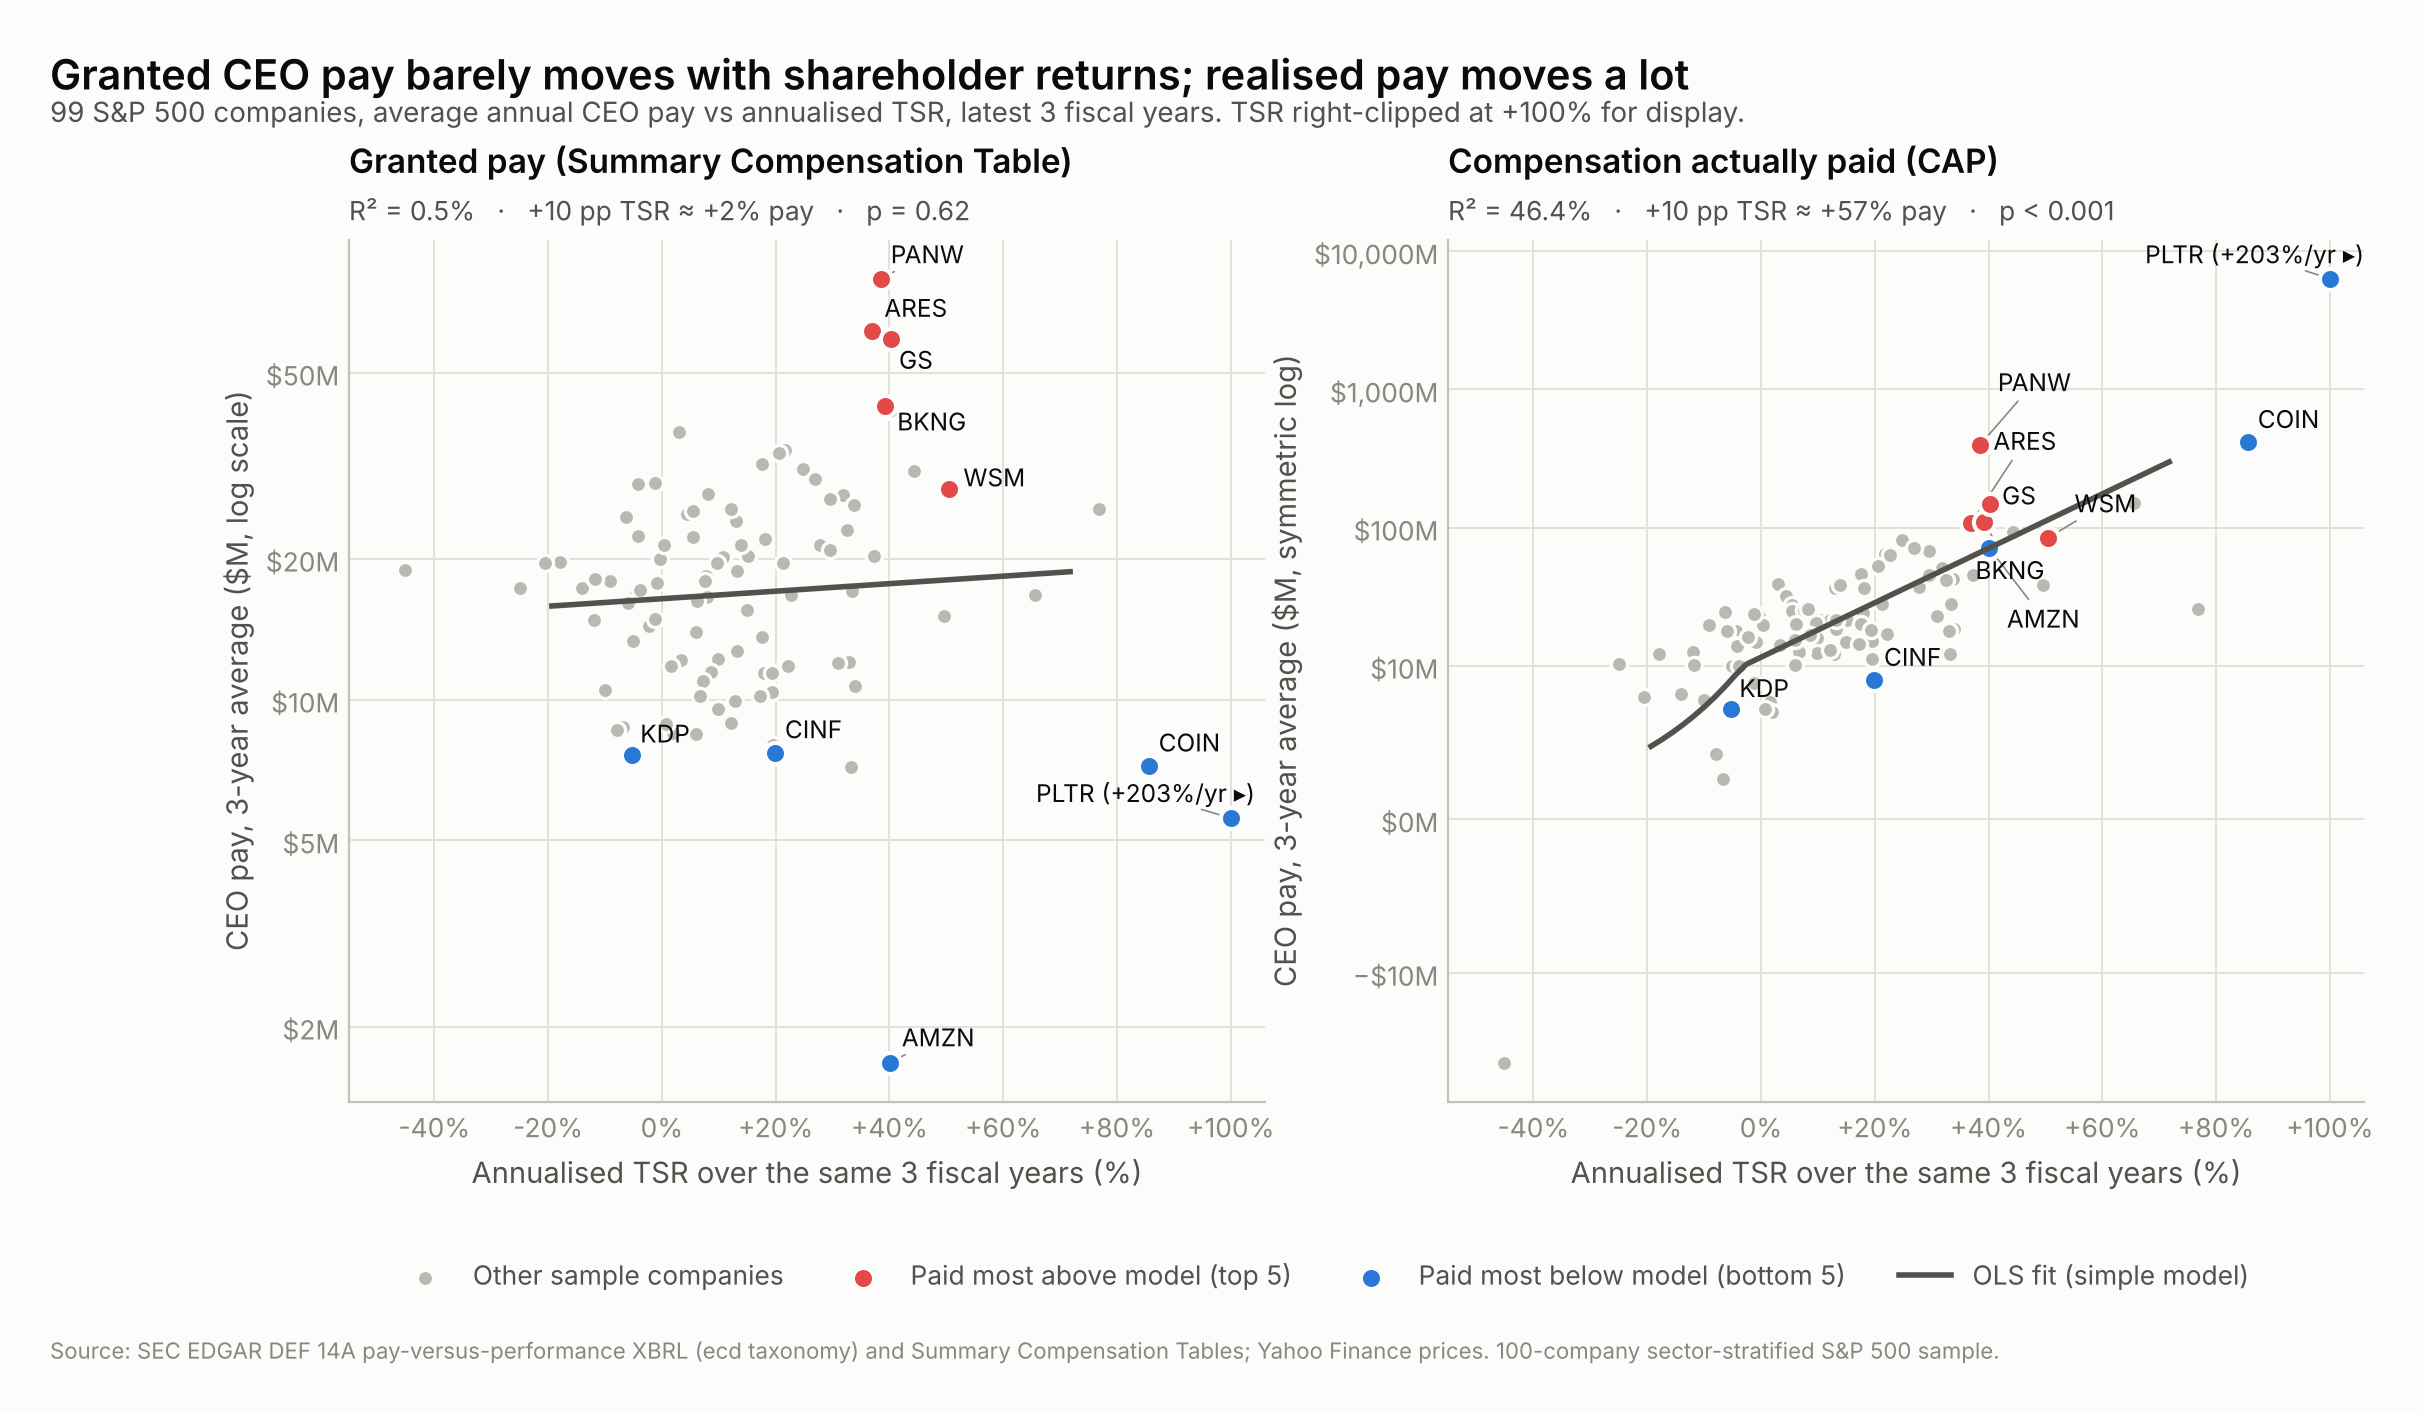

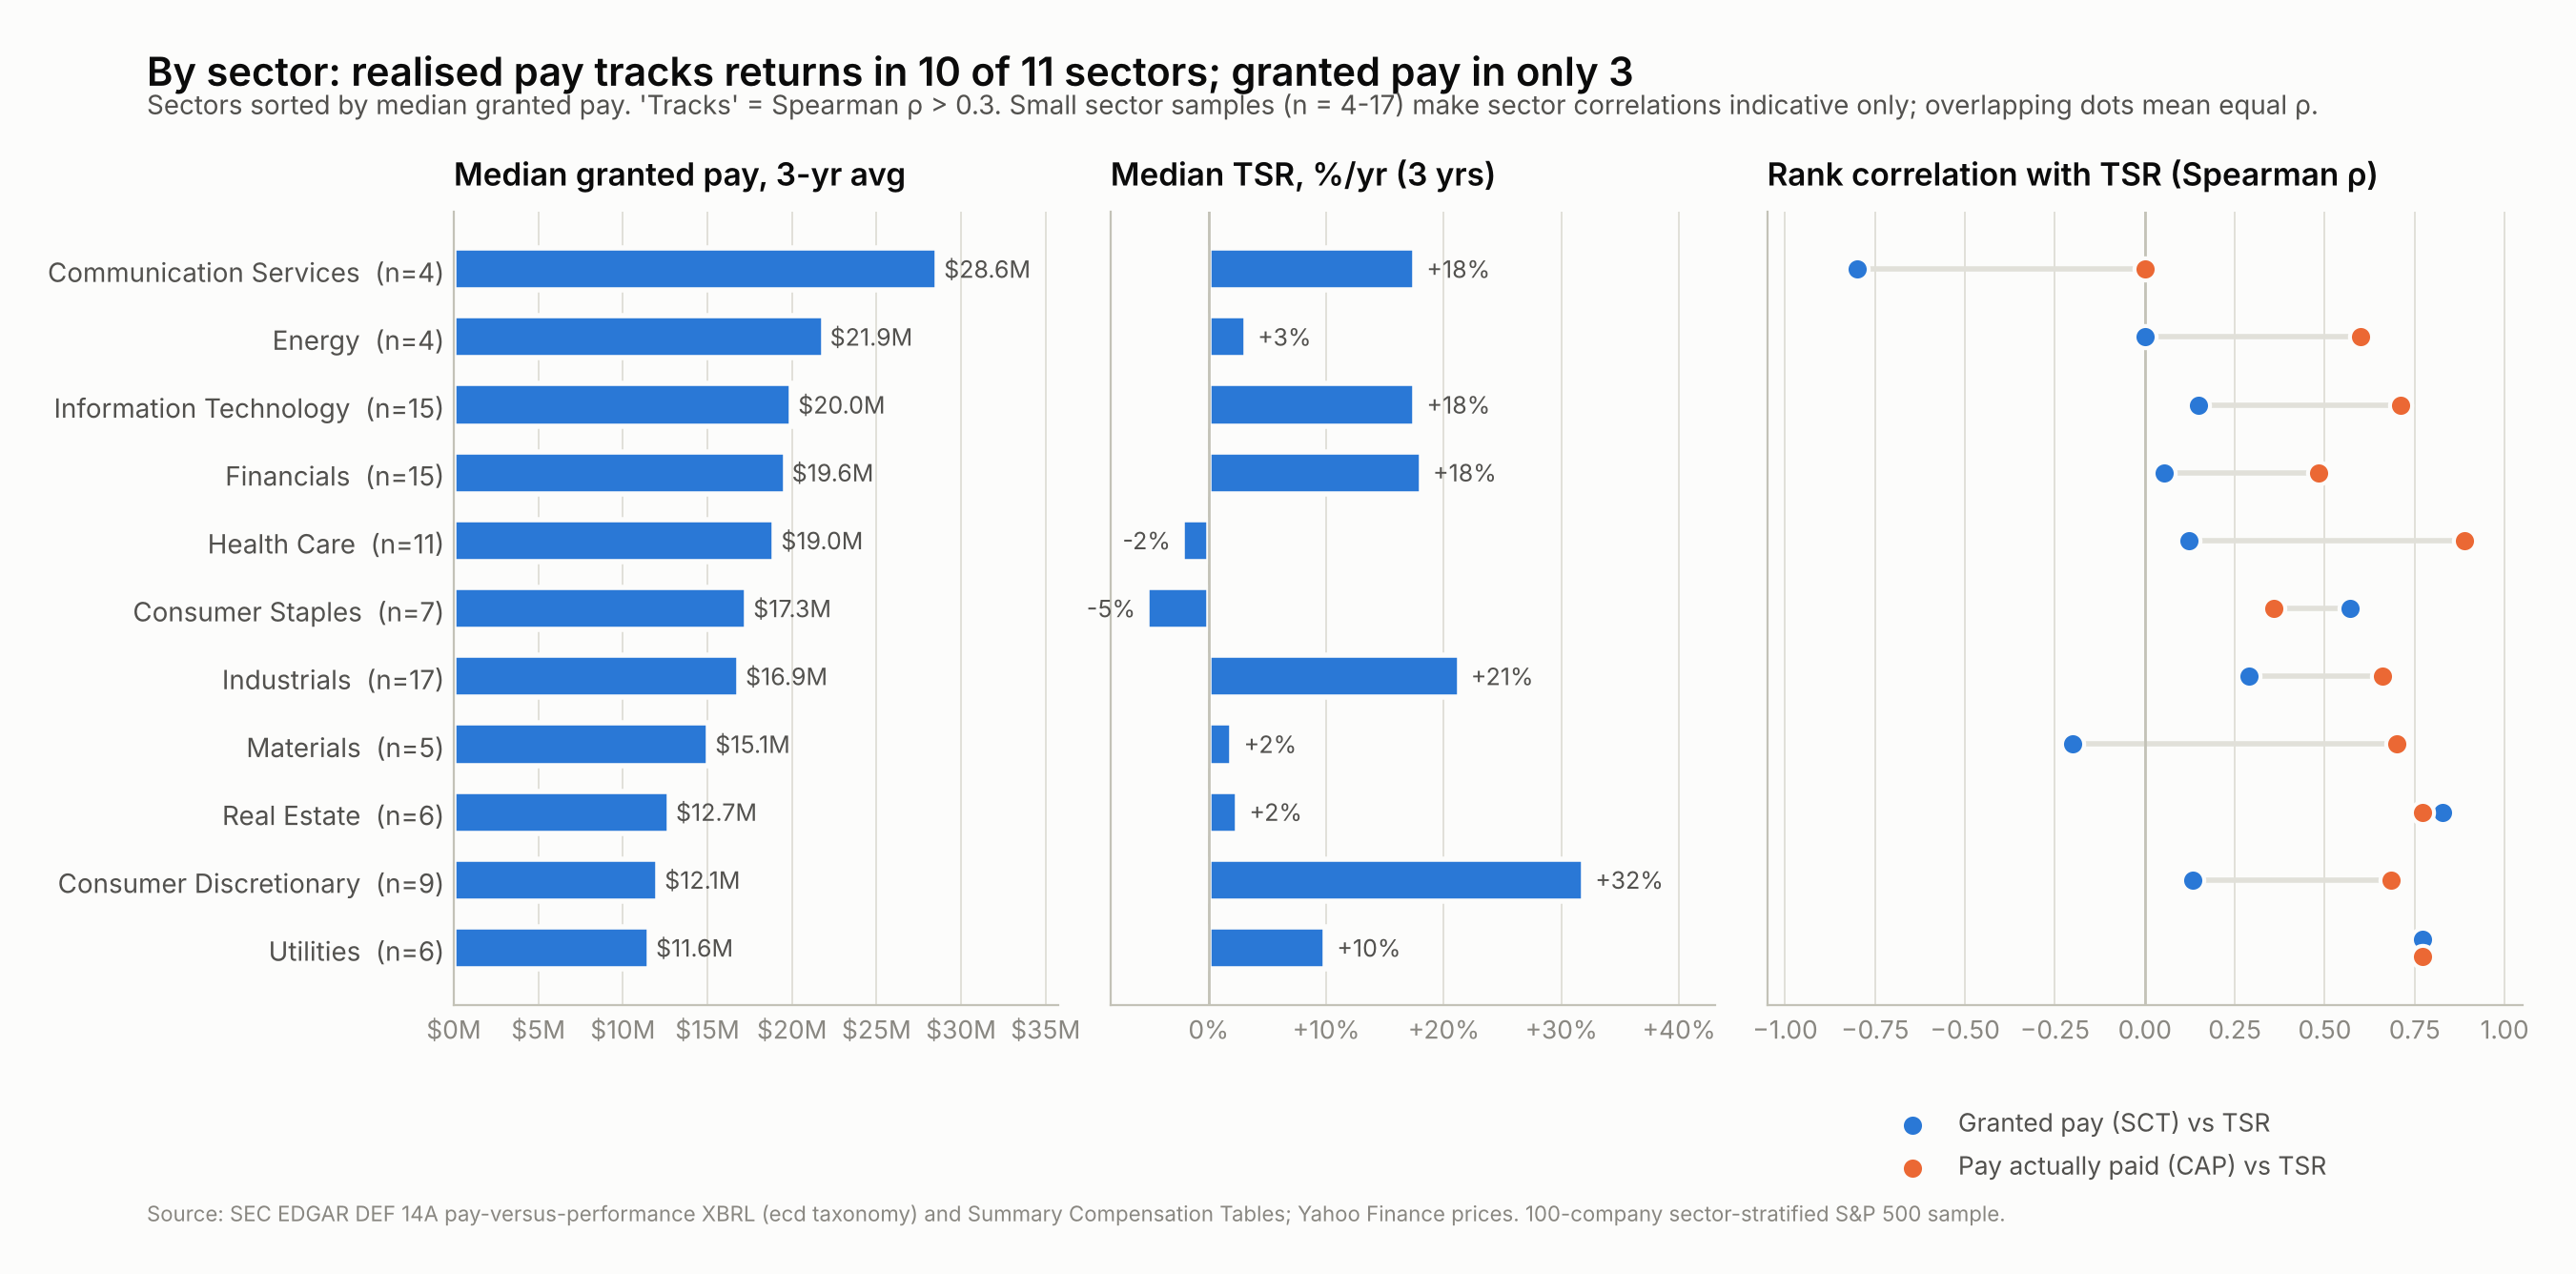

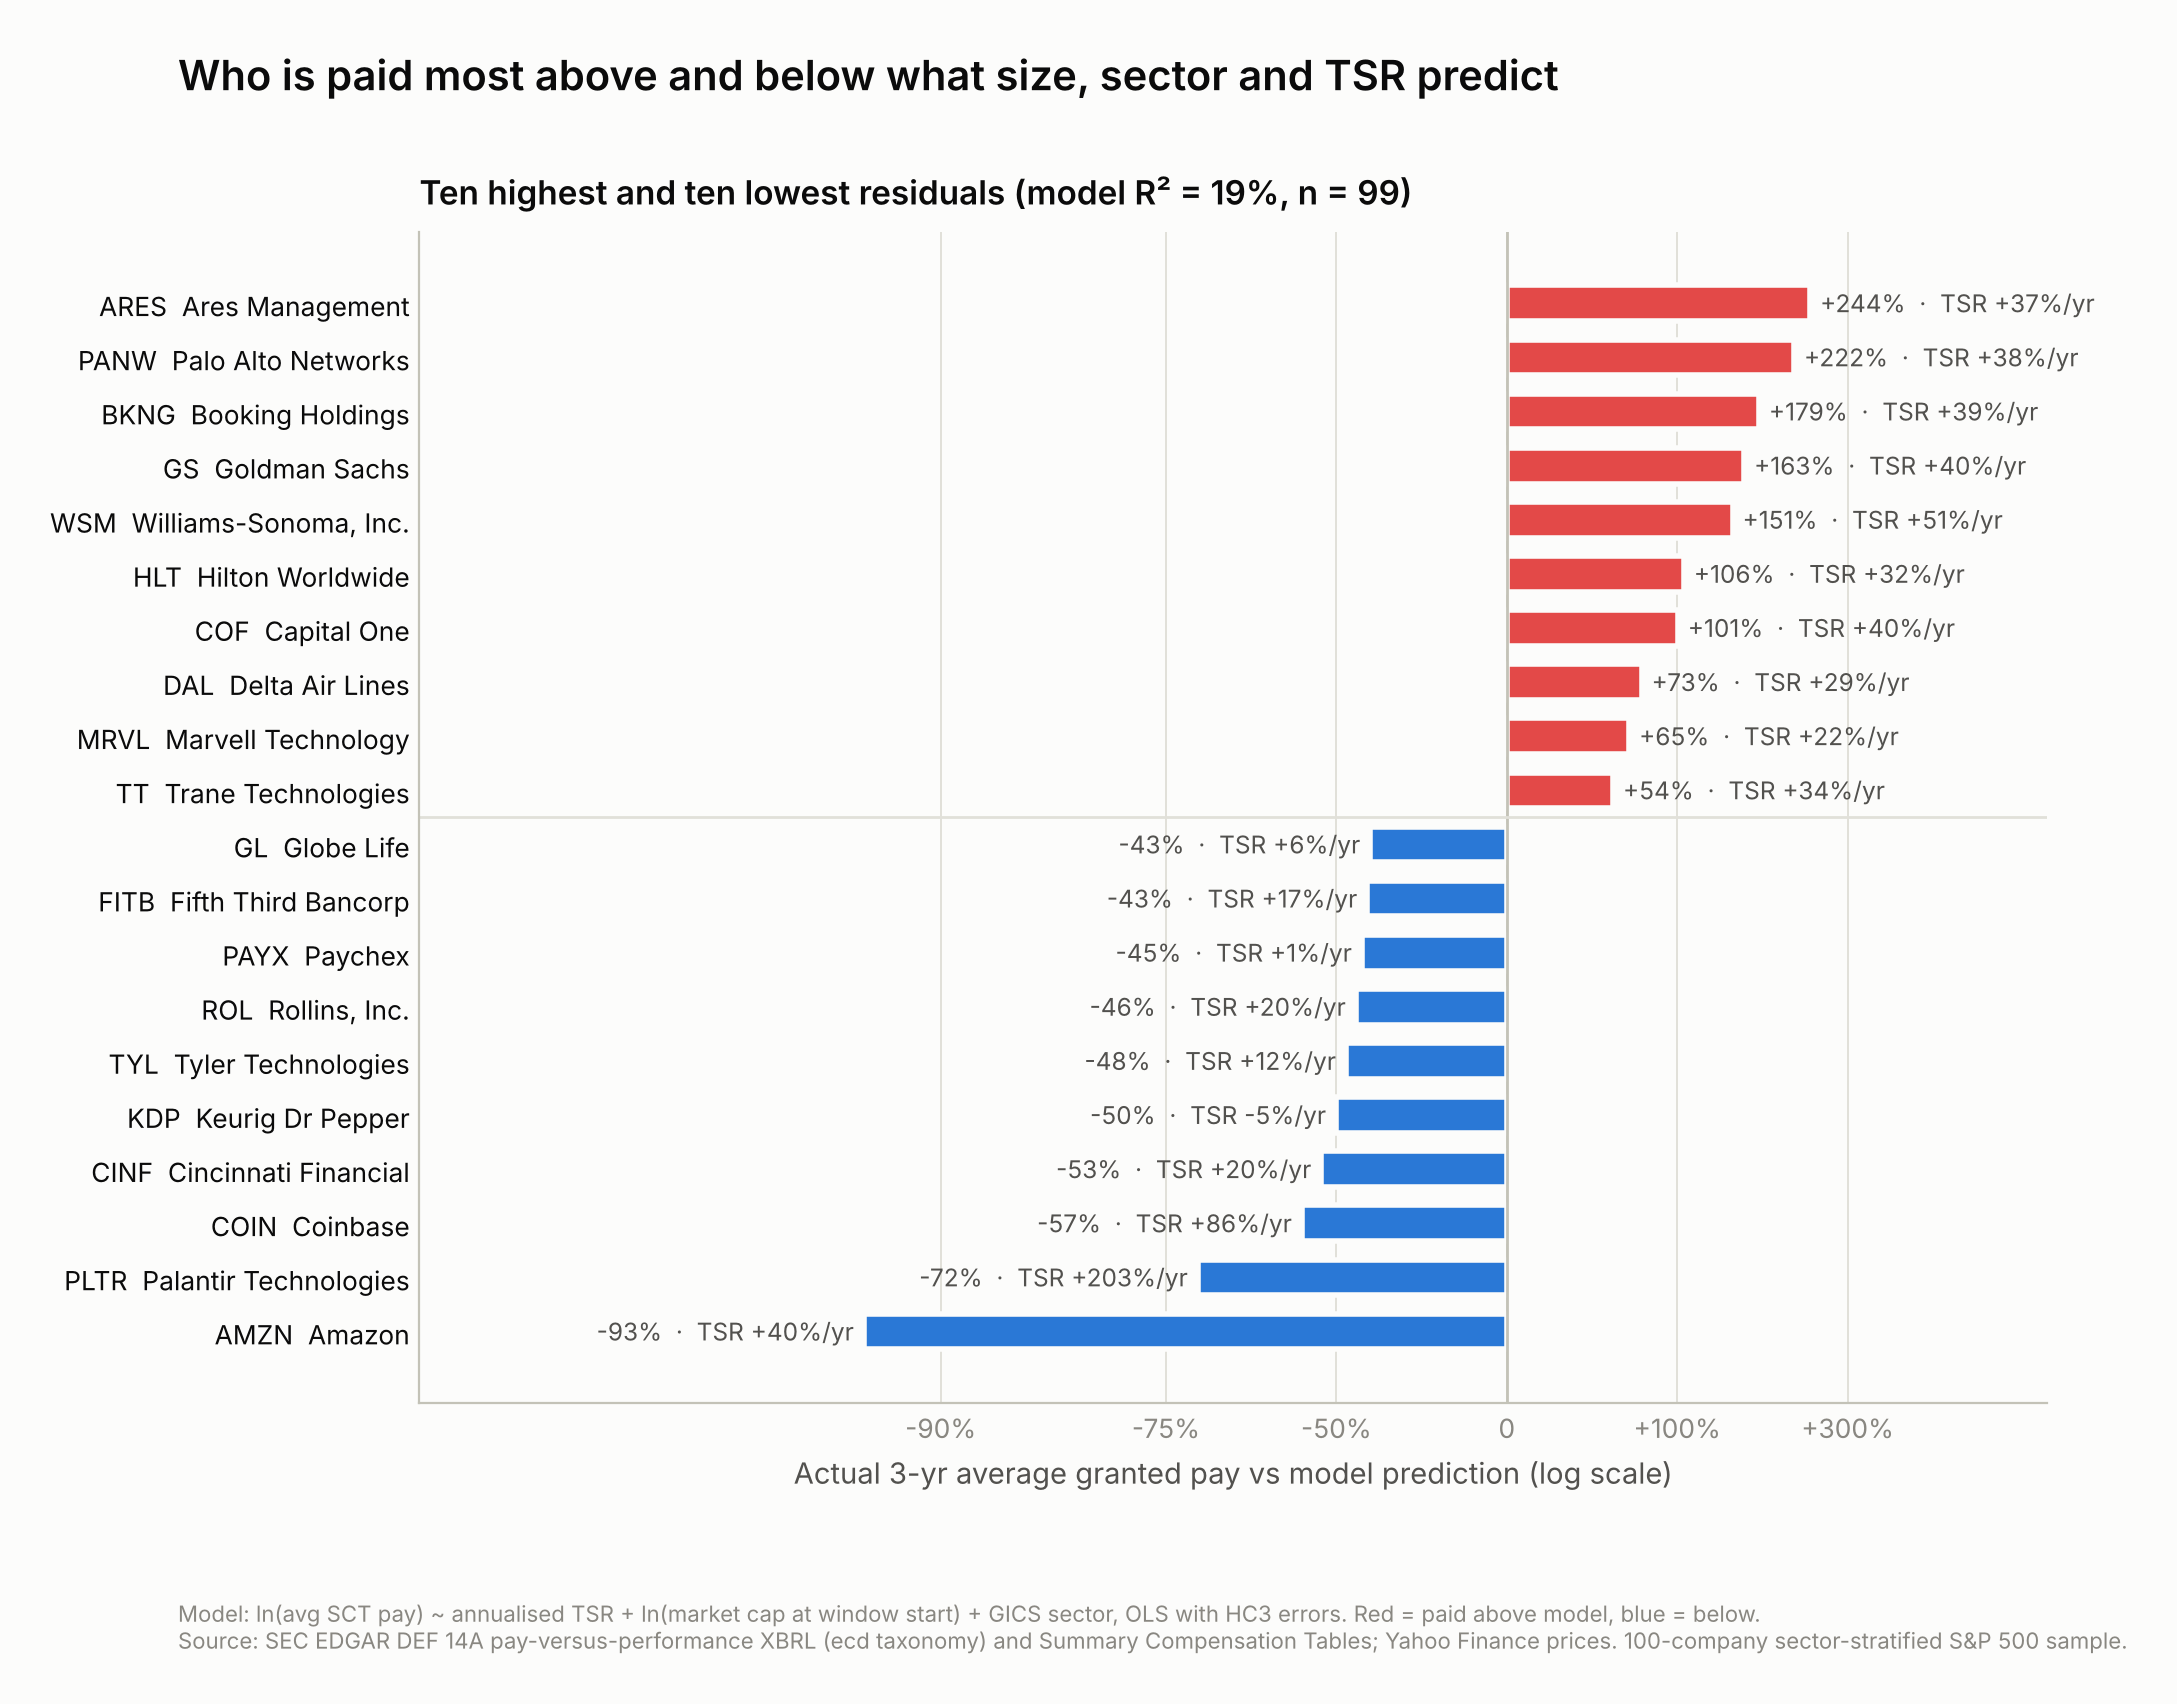

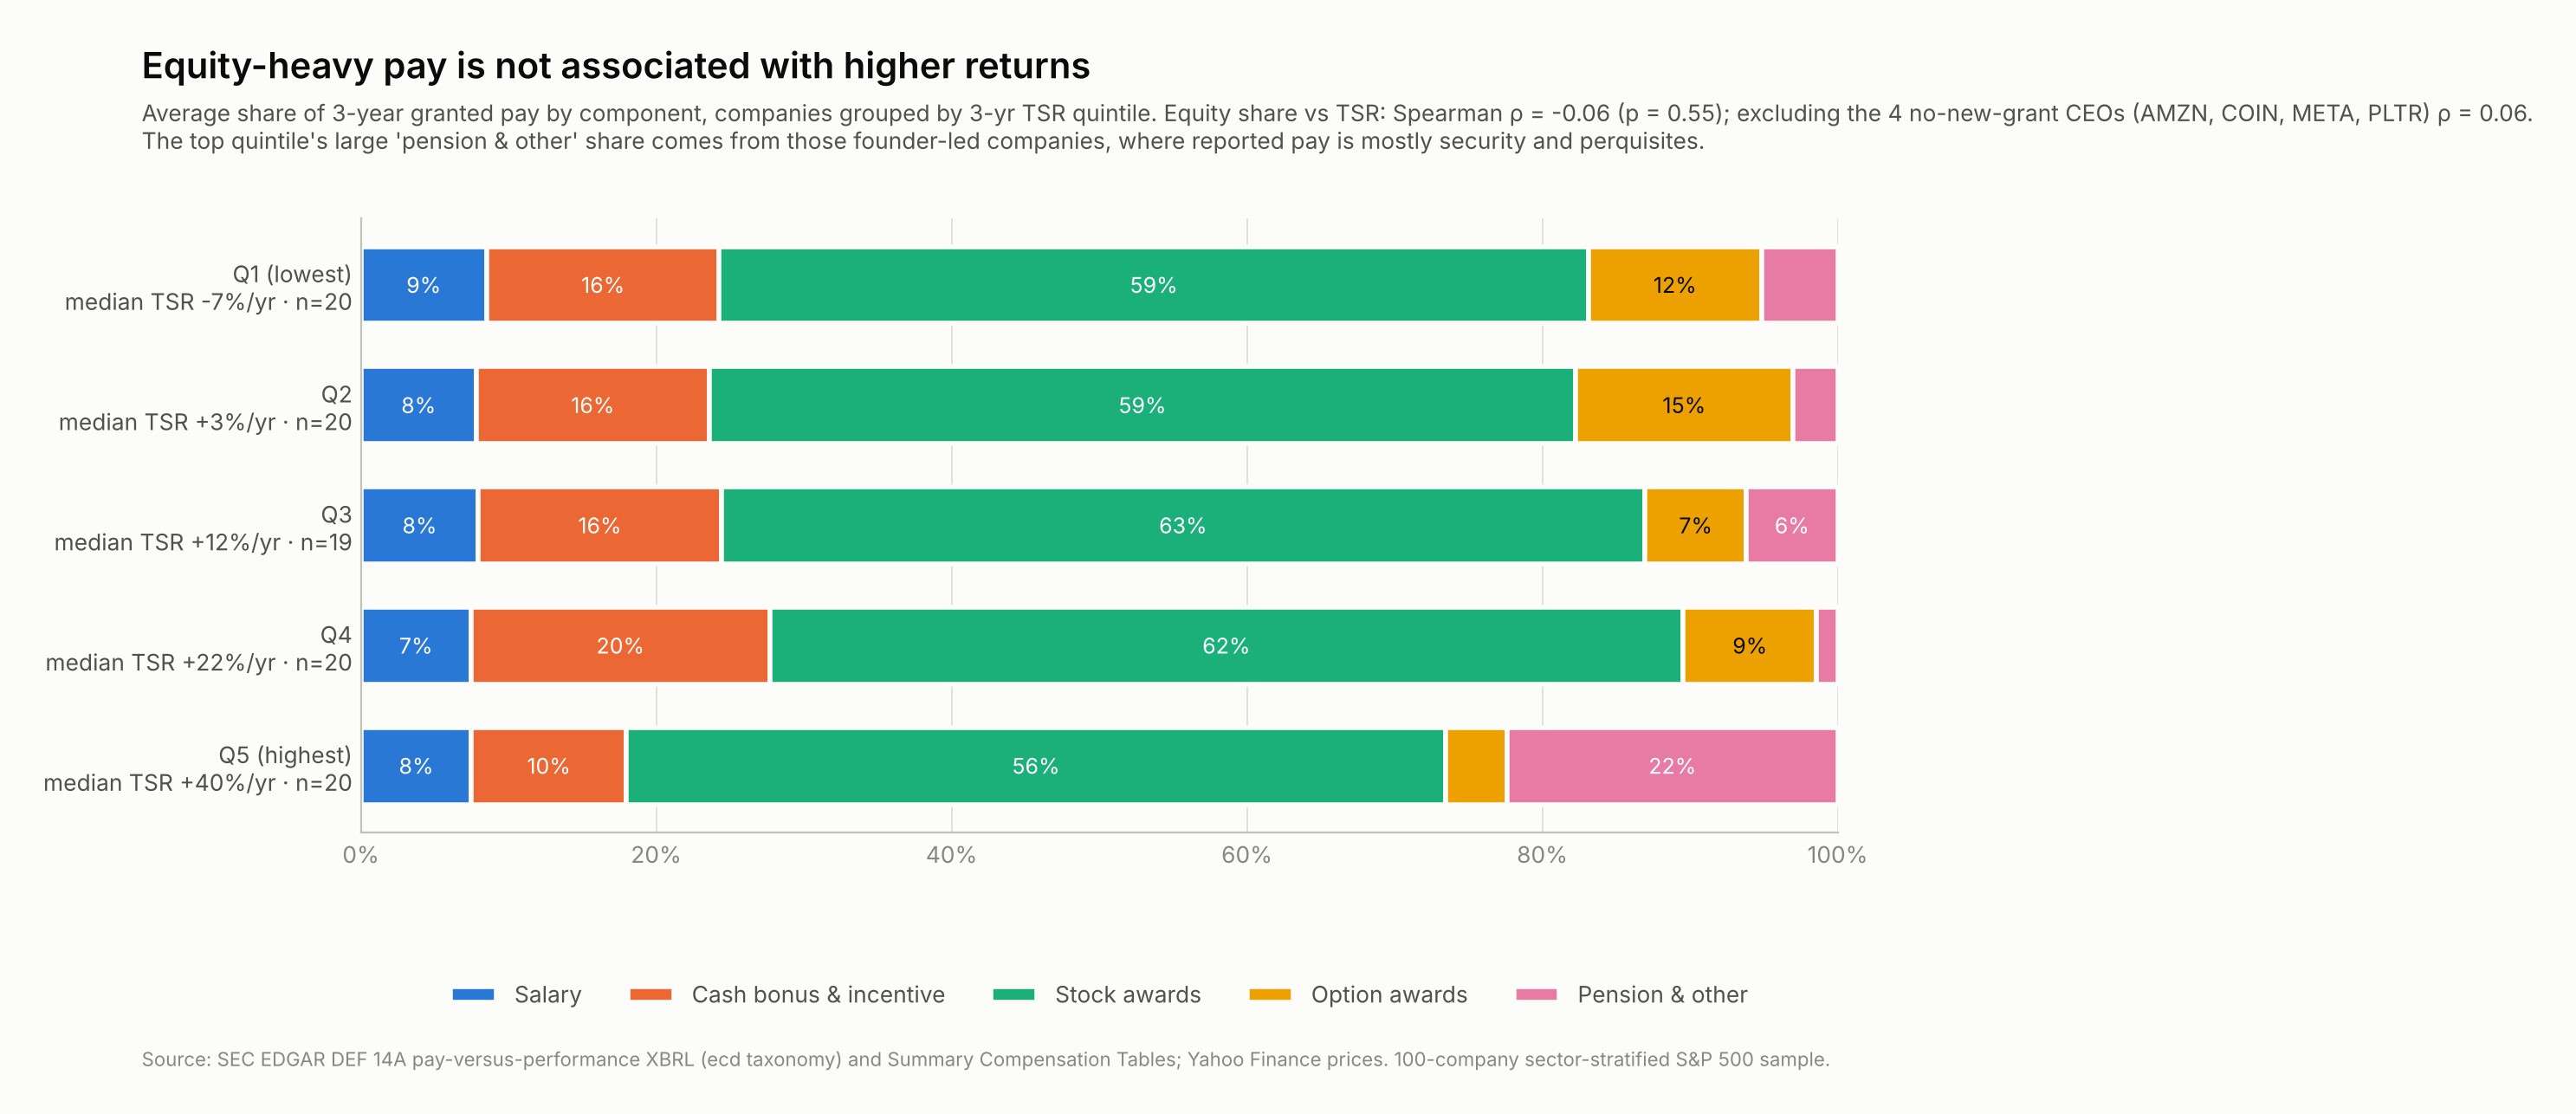

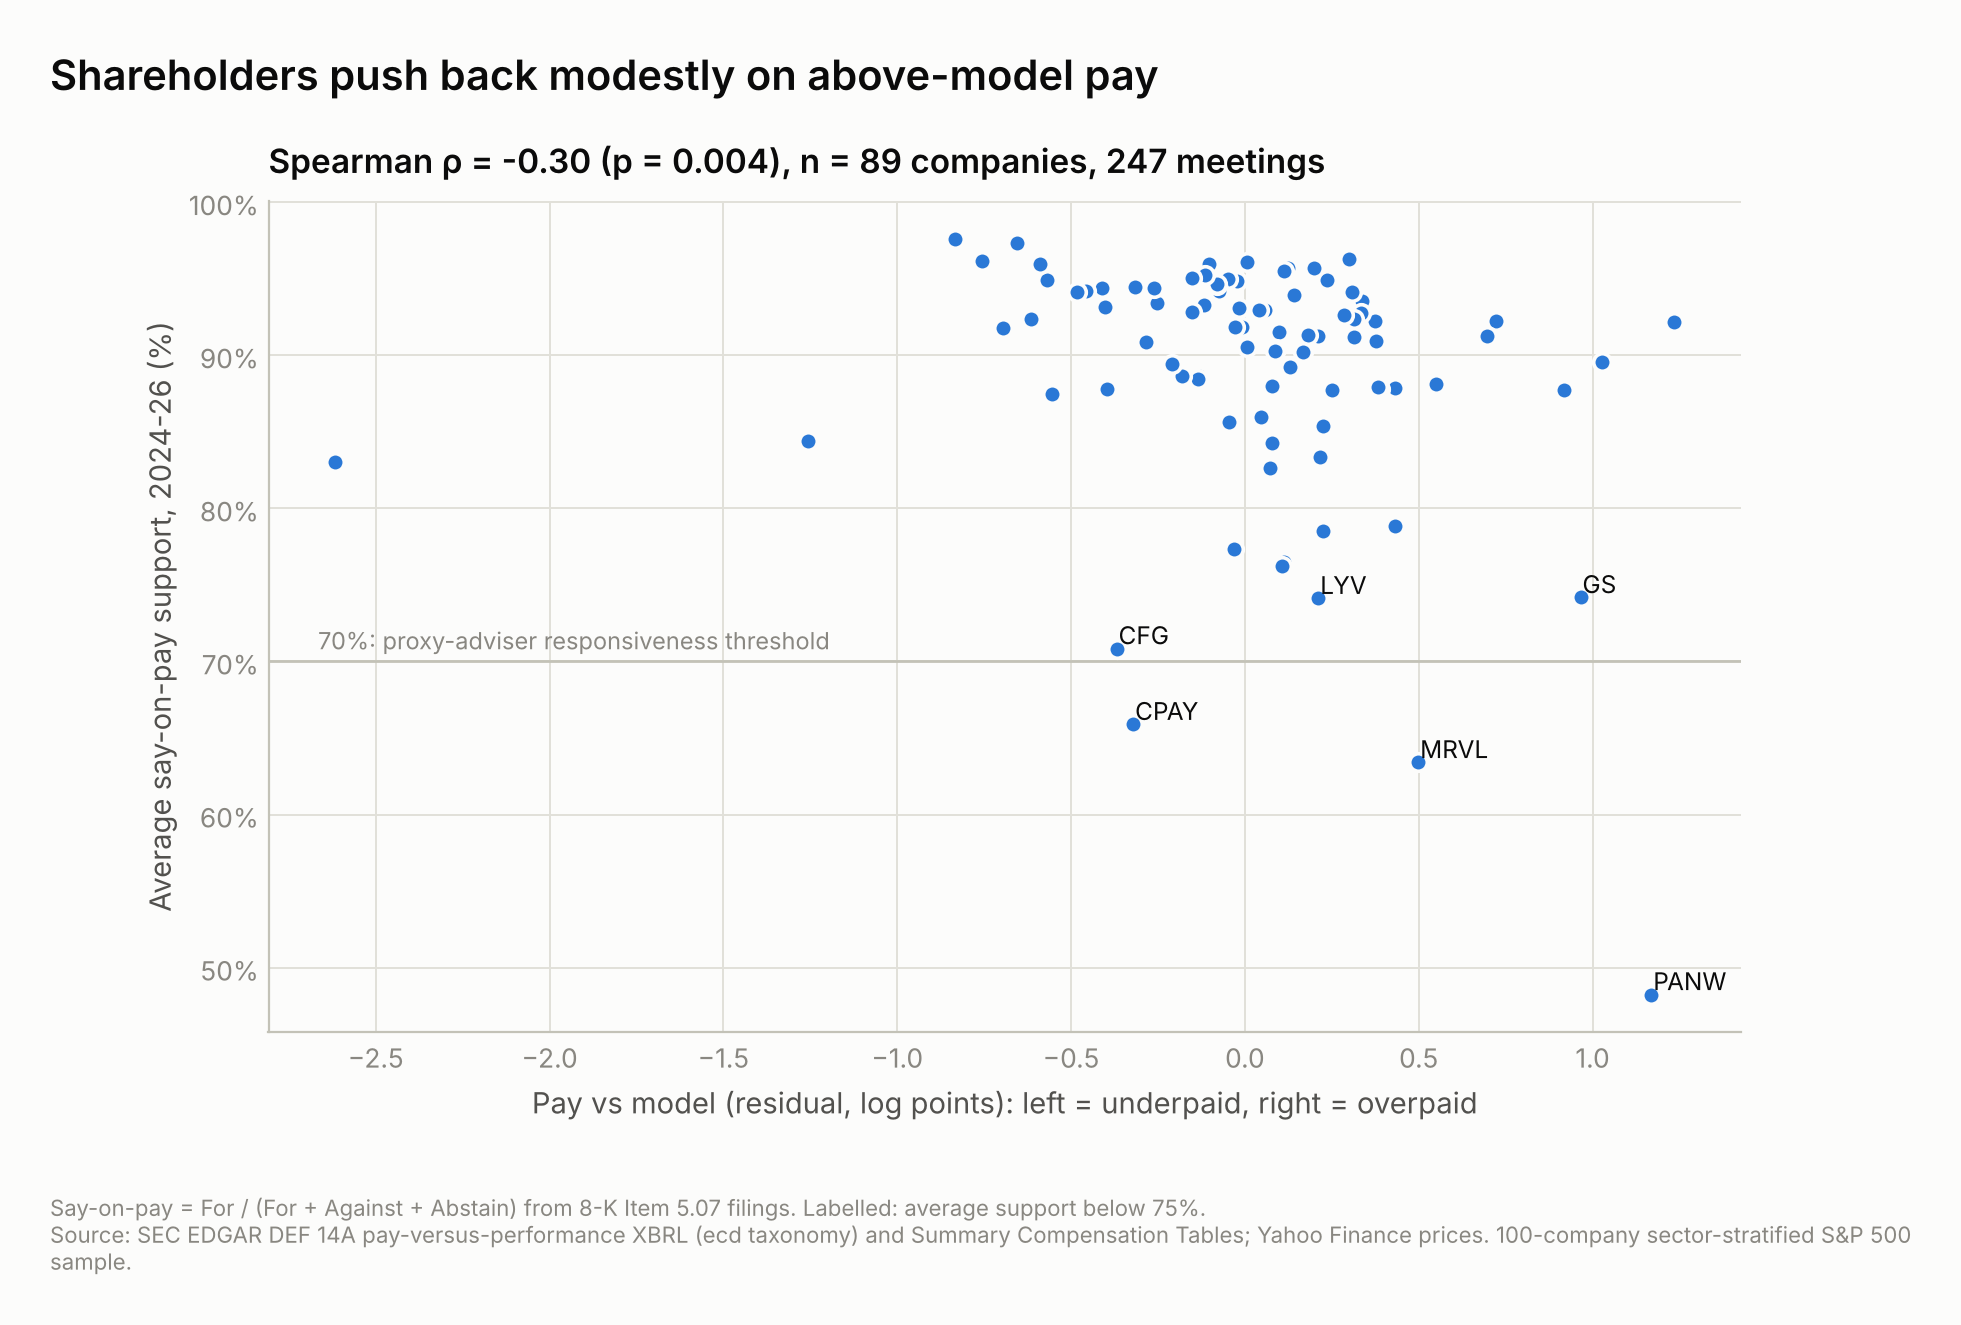

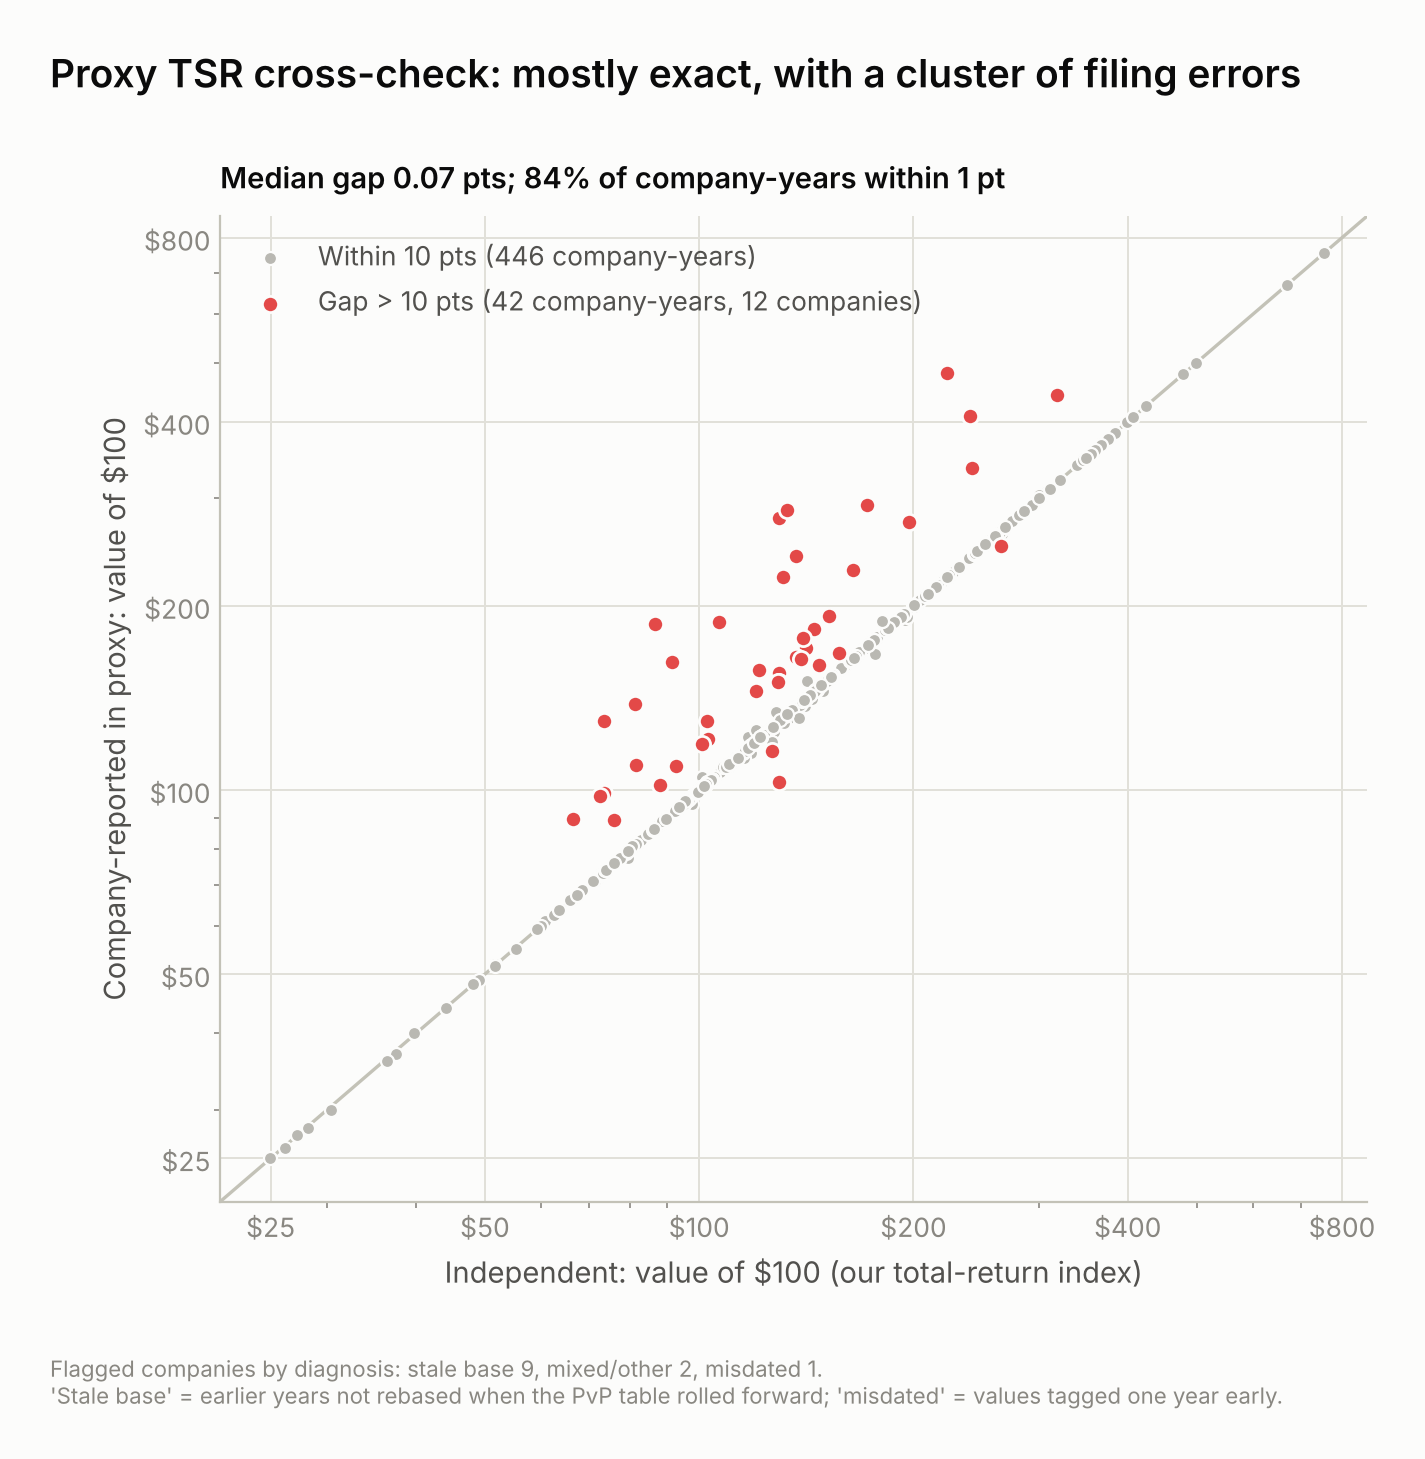

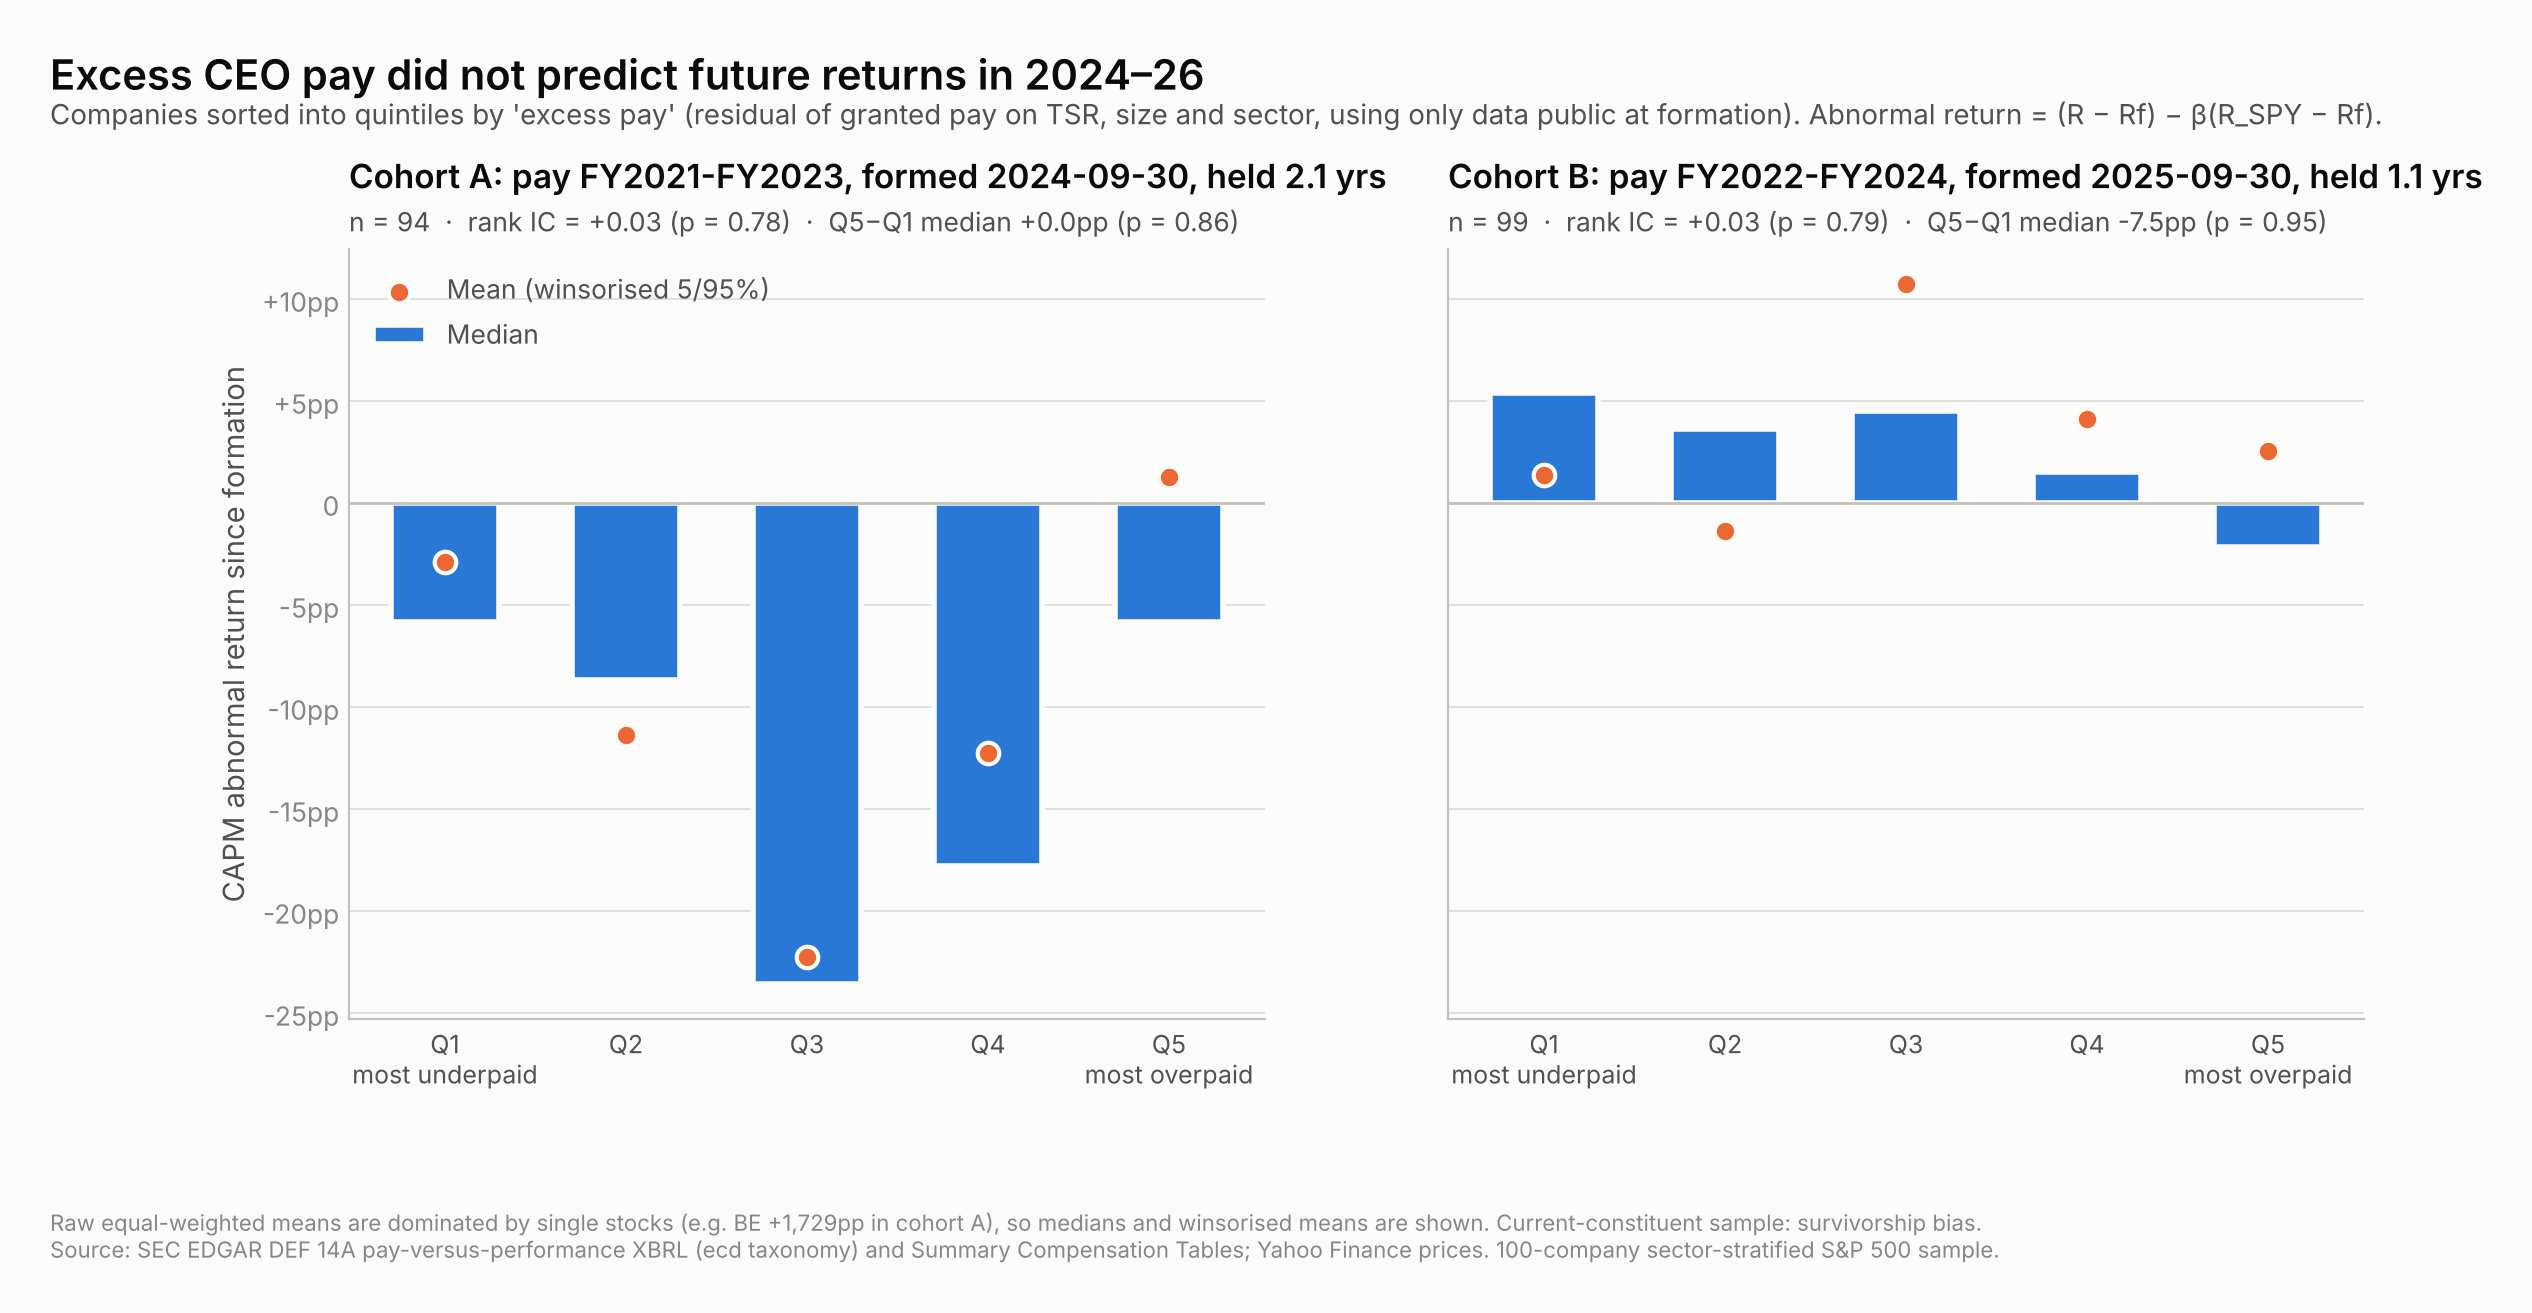

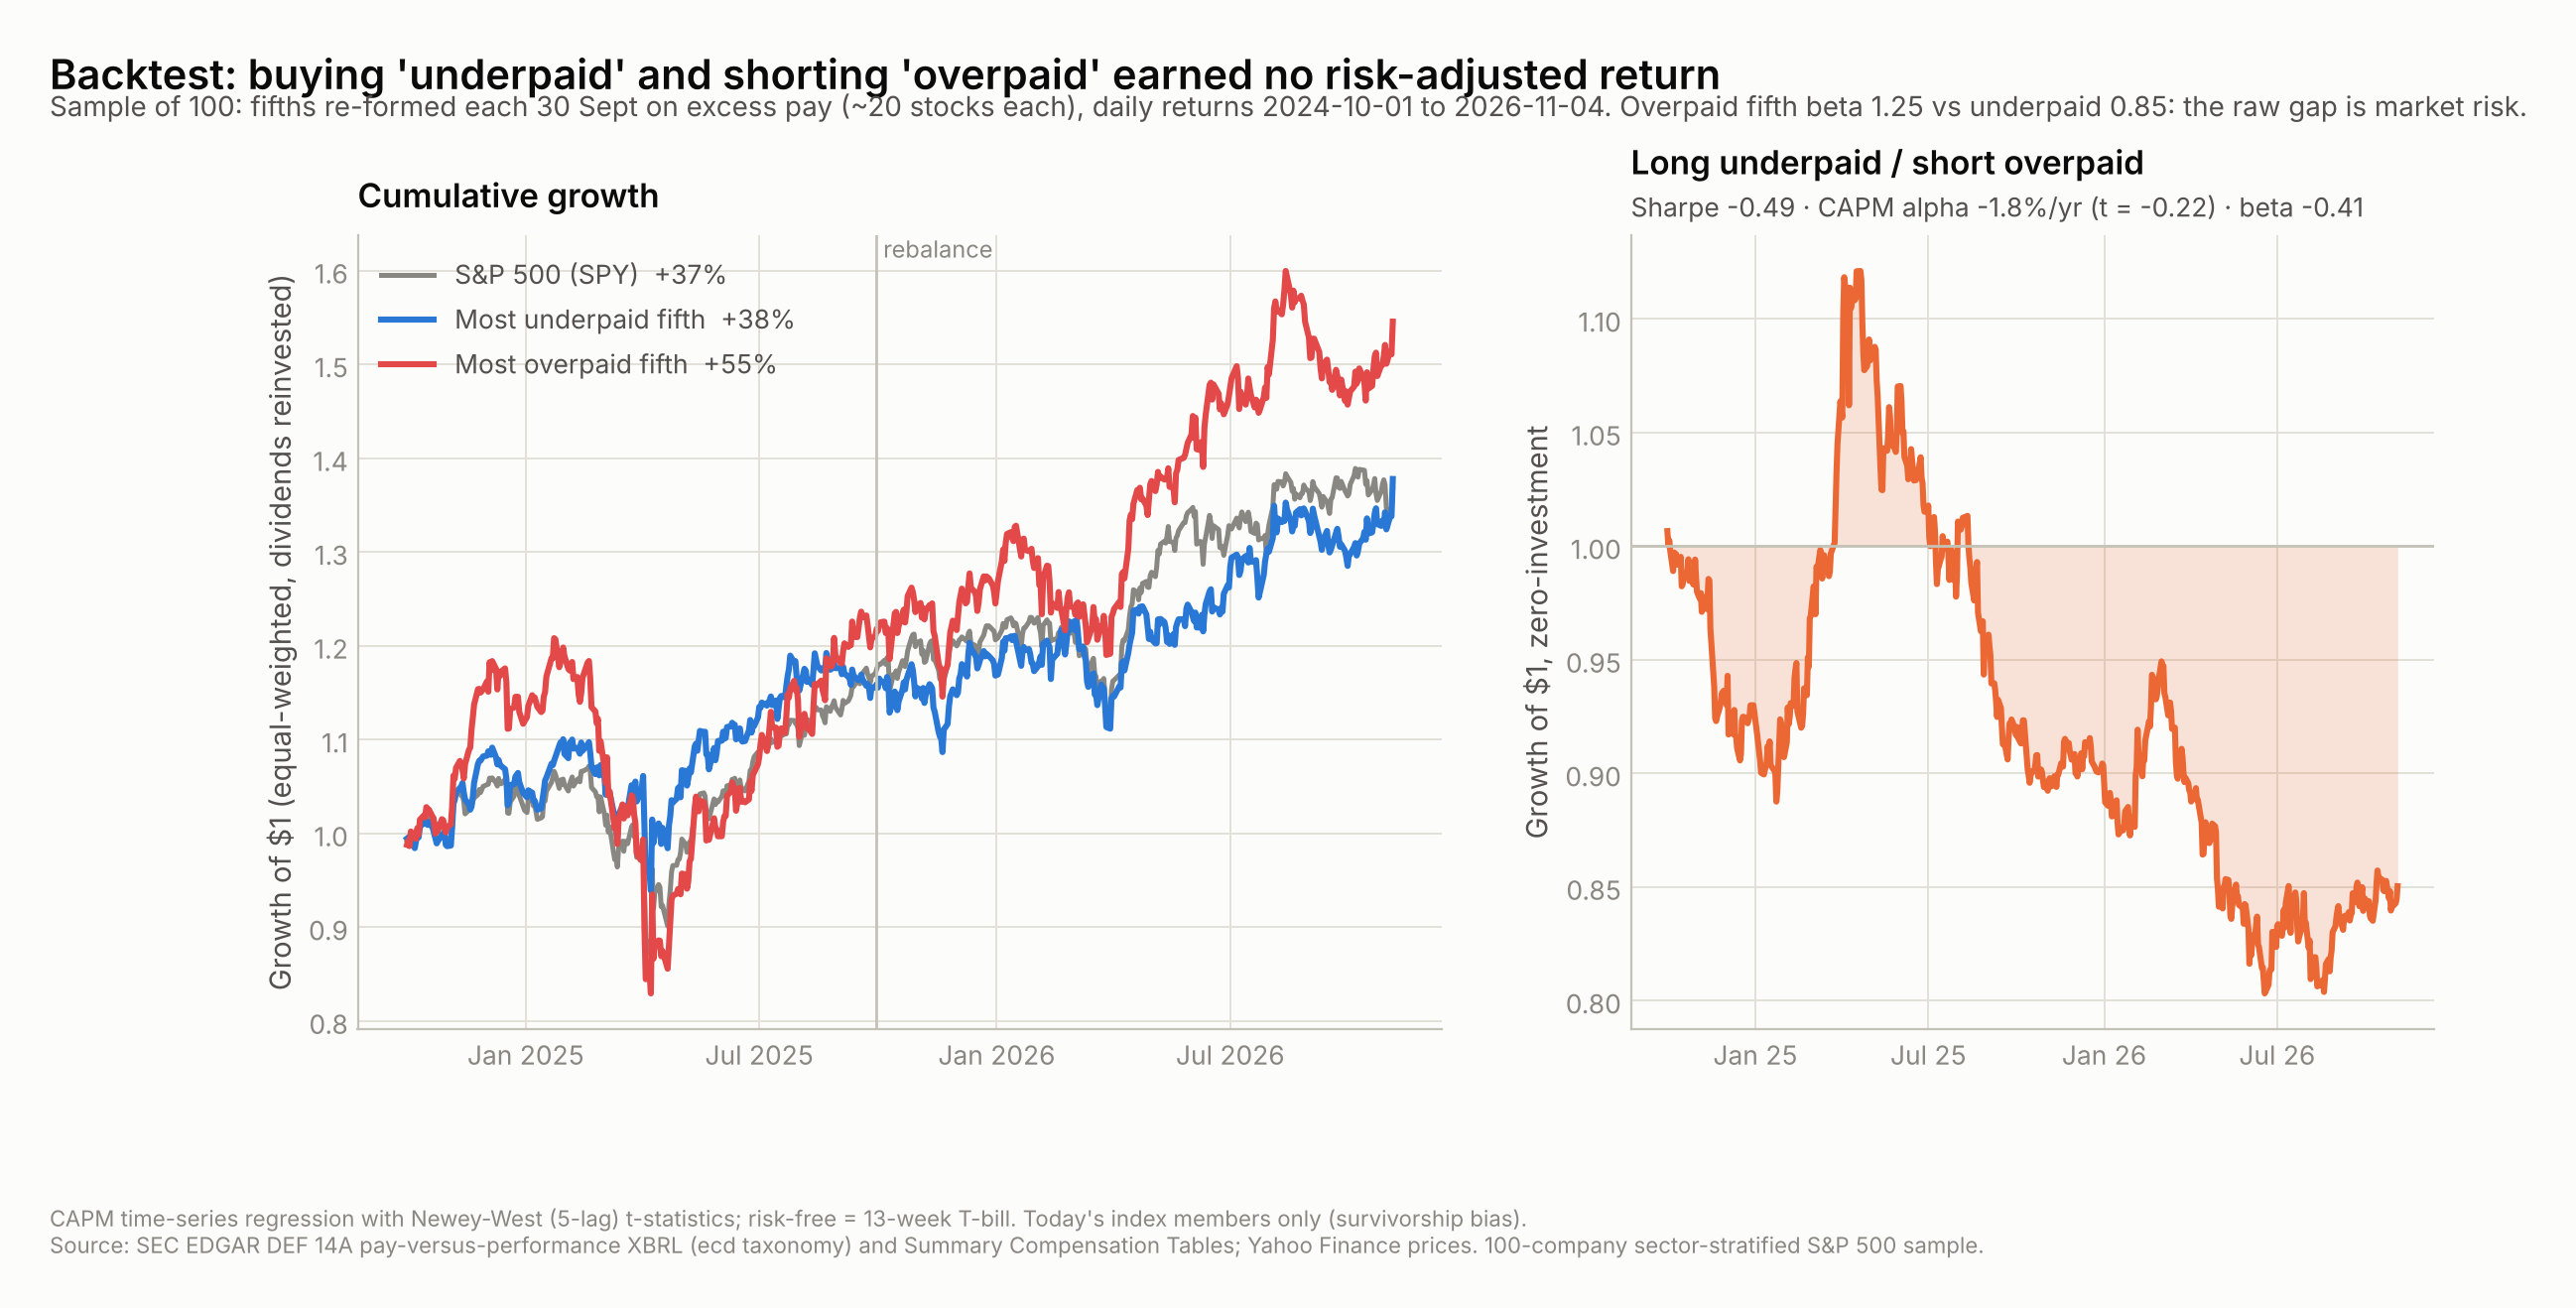

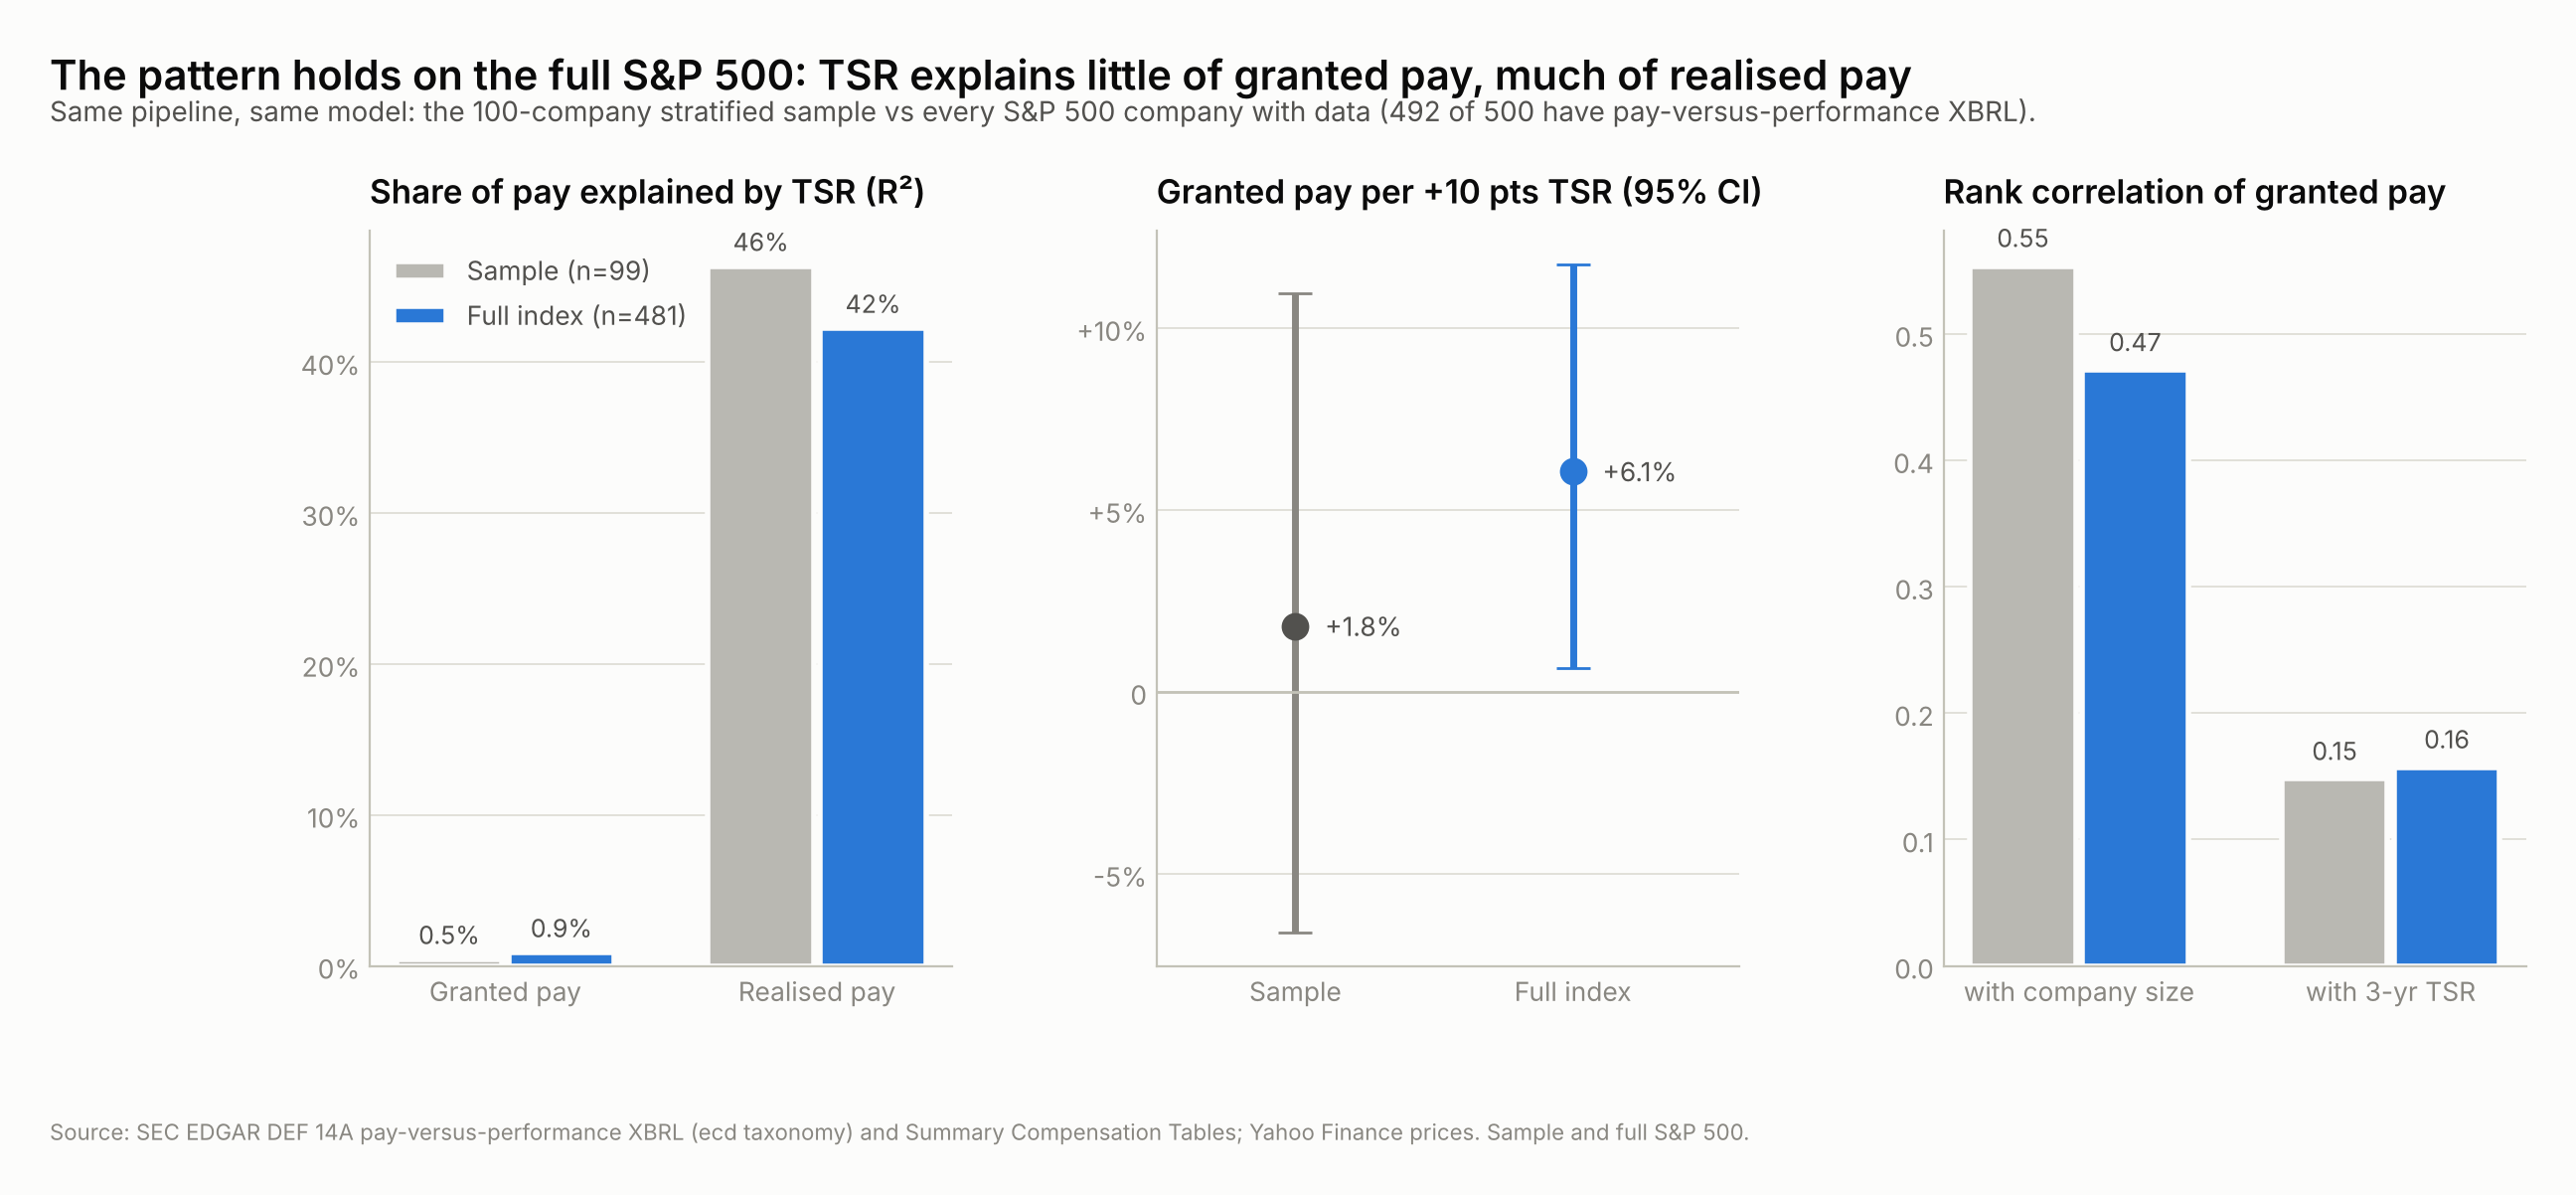

In [28]:
from src import charts
charts.run()
for f in ["01_pay_vs_tsr_scatter.png", "02_sector_breakdown.png", "03_residual_outliers.png",
          "04_pay_mix_by_tsr_quintile.png", "05_say_on_pay_vs_residual.png", "06_tsr_crosscheck.png",
          "07_strategy_test.png", "08_backtest.png", "09_replication.png"]:
    if (config.CHARTS / f).exists(): display(Image(filename=str(config.CHARTS / f), width=900))

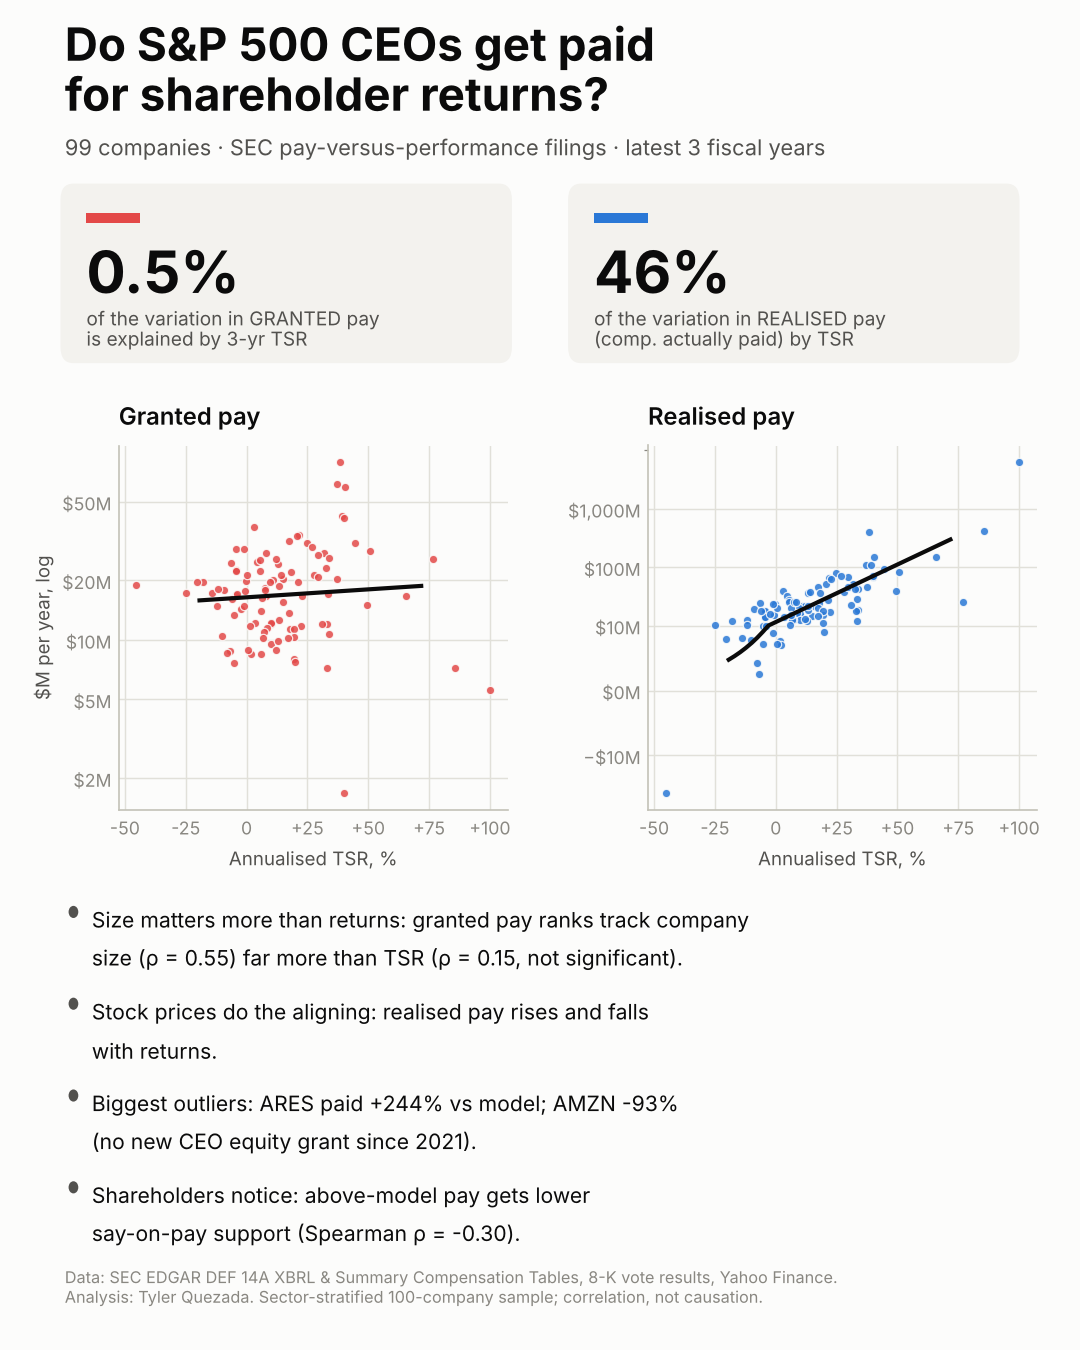

In [29]:
display(Image(filename=str(config.CHARTS / "linkedin_summary.png"), width=480))

## Conclusions

1. **Granted pay barely tracks TSR.** TSR explains about 0.5% of the cross-company variation in what boards award, and within companies pay does not respond to the same year's return.
2. **Size matters more.** Pay ranks with company size far more than with TSR. A modest TSR slope appears only once four founder/lump-grant companies are excluded, and over 5-year windows.
3. **Realised pay (CAP) tracks TSR strongly**, because CAP marks existing equity to market. Alignment comes through the stock CEOs hold.
4. **Outliers have identifiable causes.** Above-model pay at ARES, PANW, GS and OMC traces to structural or one-time awards (fee-for-equity swaps, retention mega-grants, front-loaded options). Below-model pay at AMZN, PLTR and COIN reflects founder and multi-year grants. Booking Holdings has no single cause: it is a sustained board choice.
5. **Shareholders react to the level of pay** (lower say-on-pay support for above-model pay), not to weak returns.
6. **Proxy TSR needs checking.** 12 of 100 PvP tables contain TSR errors larger than 10 points.
7. **Excess pay did not predict 2024-26 returns.** The rank IC is +0.03 in both point-in-time cohorts. A raw-mean "signal" came from a single stock.
8. **The numbers hold up.** 100/100 XBRL figures appear in the proxies, 301/301 pay-mix rows reconcile, 27/27 case-study facts are verified, and permutation, bootstrap and leave-one-out tests agree.

See `output/report/report.pdf` for the full write-up and `ASSUMPTIONS.md` for every judgment call.